<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">

# Visión por Computadora II
## Detección en imágenes fisheye: rama 3, fine-tuning sin rectificación

### Objetivo

La rama 2 corrige la imagen y deja el modelo intacto. Acá hago lo contrario: dejo la imagen fisheye como está y adapto el modelo. Un detector pre-entrenado en COCO nunca vio la deformación de una lente ojo de pez. Las convoluciones son equivariantes a traslaciones (el mismo filtro responde igual en cualquier posición), pero en una fisheye la geometría de un objeto depende de dónde está, y un peatón en el centro no se parece al mismo peatón en la periferia. El fine-tuning le muestra al modelo esas geometrías.

En el diseño 2×2 del equipo esta es la celda "con fine-tuning, sin rectificar":

| | sin fine-tuning | con fine-tuning |
|---|---|---|
| **sin rectificar** | rama 1: inferencia directa | **rama 3: este notebook** |
| **rectificado** | rama 2: proyección cilíndrica | rama 4: cilíndrica + fine-tuning |

Hago fine-tuning de YOLO11m (pre-entrenado en COCO) sobre las imágenes fisheye originales, con el mismo esquema de detección que las otras ramas: cajas rectangulares y las tres clases del equipo. Uso las 7233 imágenes del pool de entrenamiento (6148 para entrenar y 1085 para validar y elegir el checkpoint) y las 1000 de test una sola vez, al final. Las augmentaciones son las de Ultralytics por defecto; no agrego nada propio, así la diferencia con la rama 1 mide el efecto del fine-tuning y la diferencia con la rama 4 el de rectificar.

Mido lo mismo que la rama 2 y con las mismas funciones de `fisheye_utils.py`: mAP@50, mAP@50-95, mAP estratificado por excentricidad radial (centro, medio y periferia) y latencia.

Al final queda preparada una extensión, desactivada por defecto: la augmentación de distorsión radial que recomendó el profesor (`radial`), que se entrena igual que `base` y se activa agregándola a `VARIANTES`.

La teoría detrás de estas decisiones está en la sección siguiente, *Fundamento teórico*.

![flujo](../vpc2_fisheye.png)

### Fundamento teórico

Esta sección resume la teoría que sostiene las decisiones de la rama 3: por qué el fine-tuning sobre las fisheye (`base`, punto C del equipo) y por qué la augmentación de distorsión radial (`radial`, extensión). Las referencias están al final.

#### 1. El problema: proyección fisheye y equivarianza de la convolución

**Proyección.** En una cámara perspectiva, un rayo que llega con ángulo $\theta$ respecto del eje óptico cae a una distancia $r = f\tan\theta$ del centro de la imagen, que diverge cuando $\theta \to 90°$: no puede cubrir campos de 190°. Una lente ojo de pez usa una función que crece mucho más despacio, $r = \rho(\theta)$, cercana a $f\,\theta$. En WoodScape es un polinomio de cuarto orden calibrado por cámara, $\rho(\theta) = k_1\theta + k_2\theta^2 + k_3\theta^3 + k_4\theta^4$ [1].

**Deformación que depende de la posición.** La escala local de la imagen cambia con $\theta$ y deja de ser igual en todas las direcciones: en dirección radial vale $d\rho/d\theta$ y en dirección tangencial $\rho(\theta)/\sin\theta$. El mismo objeto en la periferia aparece con otras proporciones, comprimido y con sus líneas rectas curvadas.

**Equivarianza.** Una capa convolucional aplica el mismo filtro en todas las posiciones (*weight sharing*), y eso la hace equivariante a traslaciones: si el objeto se traslada, la respuesta se traslada con él [2]. El diseño supone que la estadística local de la imagen es la misma en todas partes. La fisheye rompe ese supuesto: llevar un peatón del centro al borde no traslada sus píxeles, le cambia la forma. Por eso el YOLO11m de COCO pierde el 74% de su mAP@50 entre el centro y la periferia (validación).

**Matiz.** Las CNN no son ciegas a la posición: el *zero-padding* y los campos receptivos grandes les permiten codificar la posición absoluta [3, 4]. Una red entrenada con imágenes fisheye puede aprender, en parte, a comportarse distinto según dónde está el objeto.

#### 2. Tres familias de soluciones

La literatura de percepción fisheye para conducción agrupa las soluciones en tres familias [5]:

| Familia | Qué cambia | Ejemplos | En el TP |
|---|---|---|---|
| Cambiar la imagen | se rectifica antes de detectar | undistort, proyección cilíndrica | ramas 2 y 4 |
| Cambiar el modelo | arquitectura o representación de los objetos | convoluciones deformables [6]; cajas rotadas, elipses o polígonos [7] | descartada por el profesor: agrega complejidad y no deja saber qué produjo la mejora |
| Cambiar los datos de entrenamiento | el modelo aprende la distorsión | fine-tuning sobre fisheye, augmentación de distorsión [8] | **rama 3** |

La rama 3 no toca la imagen en inferencia ni la arquitectura: cambia solo lo que el modelo ve al entrenar.

#### 3. Por qué funciona el fine-tuning (`base`, punto C)

**Transfer learning y cambio de dominio.** YOLO11m aprendió en COCO qué es un auto o una persona. Entre COCO y WoodScape hay un cambio de dominio: otra geometría (la proyección fisheye), otro punto de vista (cámaras bajas que ven el capó propio) y otra agrupación de clases (van, trailer y caravan como `vehicle`; bicicletas y motos como `two_wheeler`; el conductor como `person`).

Yosinski et al. [9] muestran que las primeras capas de una CNN aprenden rasgos genéricos (bordes, texturas) y las últimas rasgos específicos de la tarea. Como la fisheye deforma las formas desde los rasgos más básicos, y como hay datos suficientes (6148 imágenes, 74.909 cajas), conviene ajustar toda la red (sin congelar capas) partiendo de los pesos de COCO.

**Qué aprende la red.** Como la convolución es equivariante, no aprende un filtro para el centro y otro para el borde: amplía el repertorio de apariencias de cada clase. El peatón curvado e inclinado de la periferia pasa a ser otra forma posible de un peatón. El mosaico [10] y las traslaciones de las augmentaciones por defecto llevan objetos deformados de la periferia a otras posiciones, así la red aprende la forma sin atarla al lugar; el *padding* le da pistas de posición para ajustar el resto.

**Evidencia.** En validación la periferia pasa de 0.138 a 0.567 de mAP@50 (×4) y la caída del centro a la periferia baja del 74% al 17%.

#### 4. Por qué una augmentación de distorsión (`radial`, extensión)

**La augmentación como forma de enseñar una invariancia.** Una augmentación le muestra al modelo variaciones de lo mismo para que aprenda a ignorarlas [11]: el espejo enseña que un auto reflejado sigue siendo un auto, el cambio de color que la iluminación no importa. La augmentación radial enseña que el grado de distorsión de la lente no cambia lo que es el objeto.

**Por qué hace falta si ya se entrena con fisheye.** Las cuatro cámaras de WoodScape tienen lentes muy parecidas, así que el modelo puede quedar atado a esa distorsión en particular. Otro vehículo u otra cámara traen otra lente; simular distintos grados de distorsión prepara al modelo para eso. Es la recomendación del profesor para la tercera estrategia: "fine-tuning usando augmentaciones que simulen distintos grados de distorsión radial", manteniendo las mismas cajas y las mismas clases.

**Antecedente.** Ye et al. [8] generan imágenes fisheye sintéticas a partir de imágenes comunes variando al azar la focal y la posición de la cámara durante el entrenamiento, para simular cámaras distintas. La rama 3 aplica la misma idea partiendo de imágenes fisheye reales y variando el grado de distorsión.

**Formulación.** Para cada píxel de salida a distancia normalizada $r$ del centro óptico se lee el píxel de entrada a $r_{src} = r\,(1 + k\,r^2)/(1 + k)$, con $k \sim U[-0.2,\ 0.3]$ en la mitad de las imágenes. $k > 0$ da una lente más fisheye y $k < 0$ una rectificación parcial. Se aplica a cada imagen antes del mosaico, alrededor de su propio centro óptico, y las cajas se recalculan desde su perímetro.

**Qué predice la teoría y qué se midió.** Una augmentación de invariancia en general no mejora cuando los datos de prueba se parecen a los de entrenamiento, pero sí cuando cambian. Eso es lo que se observa: en validación (mismas cámaras) `radial` y `base` rinden igual, y con distorsión agregada `radial` pierde la mitad (0.03 contra 0.06 de mAP@50-95).

#### 5. Por qué distorsión radial y no otra deformación o corrección

| Alternativa | Qué hace | Por qué no |
|---|---|---|
| Rectificar como augmentation (cilíndrica o undistort, la corrección de la rama 2) | lleva la imagen a otra proyección | Saca la imagen del dominio fisheye que el modelo ve en inferencia, recorta campo de visión (la banda cilíndrica deja afuera el 4,3% de las cajas) y entrenar con imágenes rectificadas es la estrategia de la rama 4: mezclaría dos celdas del 2×2. |
| Augmentaciones afines (rotación, escala, traslación, shear) | aplican la misma transformación en toda la imagen | No dependen de la posición, así que no reproducen la distorsión de una lente. YOLO ya aplica escala y traslación en `base`. |
| Perspectiva (homografía) | simula rotar una cámara pinhole | Es otro modelo de cámara, no una lente ojo de pez. |
| Deformaciones elásticas o locales al azar | distorsiones sin modelo físico | No corresponden a ninguna lente real, pueden romper la forma de los objetos y no tienen un "grado" controlable. |
| Reproyección física a otra lente ($\rho'(\theta)$ con la calibración) | simula exactamente otra lente fisheye | Es la versión más fiel y queda como trabajo futuro: requiere invertir el modelo de lente de cada imagen y bastante más código. La distorsión radial aproximada varía el mismo grado de libertad con un solo parámetro. |

Razones a favor de la distorsión radial:

1. **Reproduce el grado de libertad que cambia entre lentes.** La distorsión fisheye es radial y simétrica alrededor del centro óptico: depende solo de la distancia al centro. Lo que diferencia una lente de otra es justamente esa función radial (equidistante, equisólida, estereográfica o el polinomio de cada calibración). Una deformación radial alrededor del centro óptico varía esa función y nada más.
2. **Es el modelo clásico de distorsión radial.** $r\,(1 + k\,r^2)$ es el término radial de primer orden del modelo de Brown–Conrady [12], el que usan las calibraciones de cámaras (por ejemplo OpenCV). Acá está normalizado por $(1 + k)$ para que la esquina más lejana quede fija.
3. **Tiene un "grado" controlable con un solo parámetro.** $k$ regula cuánta distorsión: $k > 0$ más fisheye, $k < 0$ más cerca de una rectificación, $k = 0$ la imagen original. Es literalmente "distintos grados de distorsión radial".
4. **La imagen sigue siendo fisheye.** El modelo entrena y se evalúa en el mismo dominio. La rectificación parcial aparece solo como uno de los grados ($k < 0$), al azar y sin recortar el campo de visión, y no como un preprocesamiento fijo.
5. **Respeta el esquema de detección.** Las cajas se recalculan desde su perímetro y las clases no cambian, como pidió el profesor.
6. **Es barata y segura.** Es monótona para $k > -1/3$ (la imagen no se pliega), no agrega bordes negros, tiene inversa numérica para llevar las cajas y cuesta un `cv2.remap` por imagen. Solo se usa al entrenar: no agrega costo en el auto.

#### 6. Diseño experimental: por qué dos variantes

Es un experimento controlado: se cambia un solo factor por vez, como pidió el profesor.

* **`base`** es la celda "con fine-tuning, sin rectificar" del diseño 2×2. Contra la rama 1 mide el efecto del fine-tuning y contra la rama 4 el de rectificar.
* **`radial` − `base`** mide solo el efecto de la augmentación: datos, modelo, hiperparámetros, semilla y criterio de checkpoint son idénticos.
* Usar la corrección de la rama 2 dentro de la rama 3 la convertiría en la rama 4: quedaría duplicada y se rompería el diseño.

#### 7. Limitaciones

1. La fórmula de distorsión es aproximada: trabaja con la distancia en píxeles $r$ y no con el ángulo $\theta$, y no usa la orientación de la cámara. Una versión física usaría el modelo de lente de la rama 2 para simular lentes reales distintas.
2. La prueba de robustez es en parte circular: usa la misma familia de distorsión con la que se entrenó `radial`. Falta validarla con un tipo de distorsión que no vio, por ejemplo una lente física simulada con el modelo de la rama 2.
3. `base` se entrenó en la Mac (MPS, precisión simple) y `radial` en Colab (A100, precisión mixta).
4. 30 épocas: en las dos variantes la mejor época fue la última, así que el modelo seguía mejorando.

#### Referencias

1. S. Yogamani et al., "WoodScape: A multi-task, multi-camera fisheye dataset for autonomous driving", ICCV 2019.
2. I. Goodfellow, Y. Bengio y A. Courville, *Deep Learning*, MIT Press, 2016, cap. 9.
3. M. A. Islam, S. Jia y N. D. B. Bruce, "How much position information do convolutional neural networks encode?", ICLR 2020.
4. O. S. Kayhan y J. C. van Gemert, "On translation invariance in CNNs: Convolutional layers can exploit absolute spatial location", CVPR 2020.
5. V. R. Kumar, C. Eising, C. Witt y S. Yogamani, "Surround-View Fisheye Camera Perception for Automated Driving: Overview, Survey & Challenges", IEEE Transactions on Intelligent Transportation Systems, 2023. https://arxiv.org/abs/2205.13281
6. L. Deng et al., "Restricted Deformable Convolution based Road Scene Semantic Segmentation Using Surround View Cameras", arXiv:1801.00708. https://arxiv.org/abs/1801.00708
7. H. Rashed et al., "Generalized Object Detection on Fisheye Cameras for Autonomous Driving: Dataset, Representations and Baseline", WACV 2021. https://openaccess.thecvf.com/content/WACV2021/html/Rashed_Generalized_Object_Detection_on_Fisheye_Cameras_for_Autonomous_Driving_Dataset_WACV_2021_paper.html
8. Y. Ye, K. Yang, K. Xiang, J. Wang y K. Wang, "Universal Semantic Segmentation for Fisheye Urban Driving Images", arXiv:2002.03736, 2020. https://arxiv.org/abs/2002.03736
9. J. Yosinski, J. Clune, Y. Bengio y H. Lipson, "How transferable are features in deep neural networks?", NeurIPS 2014.
10. A. Bochkovskiy, C.-Y. Wang y H.-Y. M. Liao, "YOLOv4: Optimal Speed and Accuracy of Object Detection", arXiv:2004.10934, 2020.
11. C. Shorten y T. M. Khoshgoftaar, "A survey on Image Data Augmentation for Deep Learning", Journal of Big Data, 6(60), 2019.
12. D. C. Brown, "Decentering Distortion of Lenses", Photogrammetric Engineering, 32(3), 1966.

*Las referencias 5 a 8 se verificaron en línea; el resto son trabajos conocidos citados de memoria: revisar año y venue antes de pasarlos al informe.*

### Imports y constantes

In [42]:
import os
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")  # algunas ops no tienen kernel en mps

import hashlib
import json
import sys
import time
from functools import partial
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import supervision as sv
import torch
import ultralytics
from IPython.display import Image, display
from supervision.metrics import MeanAveragePrecision
from tqdm.auto import tqdm
from ultralytics import YOLO

tqdm = partial(tqdm, mininterval=30)  # sin esto la barra deja miles de lineas en el notebook guardado

# las funciones compartidas estan en fisheye_utils.py y las de esta rama en fisheye_aug.py, en la raiz del repo
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
from fisheye_utils import (
    ANILLOS, CLASES, CONF, DEVICE, IMGSZ, NOMBRES_ANILLOS,
    a_clases_tp, cargar_gt, cargar_test, clave_calib, detector_yolo, dibujar, evaluar, radio, tabla_resultados,
)
from fisheye_aug import (
    AUG_RADIAL, CONTROL, distorsionar, distorsionar_cajas, entrenar, mapas_radiales, preparar_yolo_ds,
    puntos_adelante, radio_max,
)

In [43]:
SALIDAS = RAIZ / "outputs/rama3"
SALIDAS.mkdir(parents=True, exist_ok=True)

# ---- experimento: los mismos valores que la rama 4 en todo lo que define el entrenamiento (ver Entrenamiento)
MODELO_BASE = str(RAIZ / "yolo11m.pt") if (RAIZ / "yolo11m.pt").is_file() else "yolo11m.pt"  # el de la rama 2
BATCH = 16
VARIANTES = ["base", "radial"]  # punto C del equipo; ["base", "radial"] cuando este la corrida radial de Colab
EXTENSION_RADIAL = "radial" in VARIANTES

# ---- de donde salen los pesos de cada variante
# "mac"   : 30 epocas en esta Mac con tools/train_rama3.py desde la terminal (outputs/rama3/mac/)
# "colab" : 30 epocas en Colab con notebooks/rama3_colab.ipynb, copiada de Drive a outputs/rama3/colab/
# "local" : una prueba corta dentro del notebook (2 epocas sobre el 25% del train), solo para ver que todo corre
ORIGEN = {"base": "mac", "radial": "colab"}
ENTRENAR = any(ORIGEN[v] == "local" for v in VARIANTES)
EPOCHS = 2  # solo para la prueba local
FRACCION = 0.25  # solo para la prueba local
CLOSE_MOSAIC = 10 if EPOCHS > 10 else 0  # con pocas epocas no apago el mosaico, asi la prueba lo ejercita

CARPETAS = {"mac": SALIDAS / "mac", "colab": SALIDAS / "colab", "local": SALIDAS / "runs"}
PESOS = {v: CARPETAS[ORIGEN[v]] / f"rama3_{v}" / "weights" / "best.pt" for v in VARIANTES}

# ---- evaluacion
CONF_PRED = 0.001  # guardo las predicciones hasta 0.001 y para medir filtro a CONF (0.01), igual que la rama 2
EVALUAR_TEST = True  # el test se corre UNA vez, al final y con los pesos definitivos

# ---- extension (solo si "radial" esta en VARIANTES)
N_ROBUSTEZ = 300  # imagenes de val para la curva de robustez
K_ROBUSTEZ = [-0.2, -0.1, 0.0, 0.1, 0.2, 0.3]

print(f"ultralytics {ultralytics.__version__} | torch {torch.__version__} | supervision {sv.__version__} | device: {DEVICE}")
print(f"modelo: {MODELO_BASE} | imgsz: {IMGSZ} | batch: {BATCH} | origen de los pesos: {ORIGEN}"
      + (f" | prueba local: {EPOCHS} epocas, fraccion {FRACCION}" if ENTRENAR else ""))
for v, p in PESOS.items():
    print(f"{v}: {p} | {'ok' if p.is_file() else 'todavia no existe'}")
print(f"variantes: {VARIANTES} | conf de las metricas: {CONF}" + (f" | augmentacion radial: {AUG_RADIAL}" if EXTENSION_RADIAL else ""))

ultralytics 8.4.164 | torch 2.14.0 | supervision 0.30.5 | device: mps
modelo: /Users/kr/Especialidad/vision-computadora-II-tp-final/yolo11m.pt | imgsz: 640 | batch: 16 | origen de los pesos: {'base': 'mac', 'radial': 'colab'}
base: /Users/kr/Especialidad/vision-computadora-II-tp-final/outputs/rama3/mac/rama3_base/weights/best.pt | ok
radial: /Users/kr/Especialidad/vision-computadora-II-tp-final/outputs/rama3/colab/rama3_radial/weights/best.pt | ok
variantes: ['base', 'radial'] | conf de las metricas: 0.01 | augmentacion radial: {'p': 0.5, 'k_min': -0.2, 'k_max': 0.3}


### Datos para Ultralytics

`convert_to_yolo.py` deja las etiquetas en `outputs/yolo_ds/labels/` y unas listas de rutas que apuntan a `rgb_images/`. Así como está no sirve para entrenar: Ultralytics encuentra la etiqueta de cada imagen reemplazando `/images/` por `/labels/` en su ruta, y como las imágenes están en `rgb_images/` no encuentra ninguna y entrena todo como fondo, con un simple warning.

`preparar_yolo_ds` arma la estructura estándar sin copiar ni recomprimir imágenes: `images/<split>/` con enlaces simbólicos a las PNG originales y `labels/<split>/` con las etiquetas de `convert_to_yolo.py`. Al final controla los números del equipo: 6148 / 1085 / 1000 imágenes y 74.909 / 13.176 / 11.910 cajas.

In [44]:
DATA, conteo = preparar_yolo_ds(
    listas=RAIZ / "outputs/yolo_ds", etiquetas=RAIZ / "outputs/yolo_ds/labels",
    imagenes=RAIZ / "rgb_images", salida=SALIDAS / "yolo_ds",
)
print(DATA.read_text())
pd.DataFrame(conteo, index=["imagenes", "cajas"]).T

# Generado por fisheye_aug.preparar_yolo_ds
path: /Users/kr/Especialidad/vision-computadora-II-tp-final/outputs/rama3/yolo_ds
train: images/train
val: images/val
test: images/test
nc: 3
names: ['vehicle', 'person', 'two_wheeler']



,imagenes,cajas
train,6148,74909
val,1085,13176
test,1000,11910


Para evaluar armo el ground truth de validación con las mismas funciones que `cargar_test` usa para el test (`cargar_gt` y la calibración de cada imagen), así val y test se miden igual que en la rama 2. El centro óptico sale de la calibración, no del centro geométrico.

In [45]:
def cargar_split(lista):
    # como cargar_test de fisheye_utils, pero para cualquier lista de convert_to_yolo (la uso para val)
    nombres = [Path(l).name for l in Path(lista).read_text().split()]
    man = pd.read_csv(RAIZ / "splits/manifest.csv").set_index("filename")
    df = pd.DataFrame({"filename": nombres, "camera": man.loc[nombres, "camera"].values})
    df["stem"] = df["filename"].str.replace(".png", "", regex=False)
    df["ruta"] = df["filename"].map(lambda f: RAIZ / "rgb_images" / f)
    gts = [cargar_gt(s, ann_dir=RAIZ / "instance_annotations") for s in df["stem"]]
    df["gt_cajas"] = [g[0] for g in gts]
    df["gt_clases"] = [g[1] for g in gts]
    df["calib"] = [clave_calib(s, c) for s, c in zip(df["stem"], df["camera"])]
    intr = df["calib"].map(lambda c: json.loads(c)["intrinsic"])
    df["cx0"] = intr.map(lambda i: i["cx_offset"] + i["width"] / 2 - 0.5)  # centro optico real
    df["cy0"] = intr.map(lambda i: i["cy_offset"] + i["height"] / 2 - 0.5)
    df["W"] = intr.map(lambda i: i["width"])
    df["H"] = intr.map(lambda i: i["height"])
    return df


val = cargar_split(RAIZ / "outputs/yolo_ds/val.txt")
n_val = sum(len(c) for c in val["gt_clases"])
assert (len(val), n_val) == CONTROL["val"], (len(val), n_val)
print(f"val: {len(val)} imagenes | {n_val} cajas | por camara: {val['camera'].value_counts().sort_index().to_dict()}")

r_gt = np.concatenate([radio(f.gt_cajas, f) for f in val.itertuples()])
print(pd.cut(r_gt, ANILLOS, labels=NOMBRES_ANILLOS, right=False).value_counts().sort_index())

val: 1085 imagenes | 13176 cajas | por camara: {'FV': 268, 'MVL': 272, 'MVR': 283, 'RV': 262}
centro       2110
medio        7285
periferia    3781
Name: count, dtype: int64


### Entrenamiento

El entrenamiento lo hace `entrenar` de `fisheye_aug.py`. Con la variante `base` usa el trainer de Ultralytics sin cambios: lo único que agrega la función es fijar los parámetros. La rama 4 entrena con su propio código (`finetune_utils.py`), con los mismos valores en todo lo que define el entrenamiento; la tabla marca dónde difiere.

| parámetro | valor | por qué |
|---|---|---|
| modelo | `yolo11m.pt` (COCO) | el mismo que eligió la rama 2, en el codo de precisión contra latencia |
| imgsz | 640 | igual en todas las ramas |
| batch | 16 | la rama 4 usa 2 por la memoria de su GPU. Ultralytics acumula gradientes hasta un batch nominal de 64 en las dos, así que cada paso de optimización ve 64 imágenes y el weight decay es el mismo; cambia que BatchNorm calcula sus estadísticas sobre lotes más chicos |
| optimizador | `auto`: AdamW, lr 0.001429 | Ultralytics lo elige a partir del batch nominal, así que es el mismo en la rama 4 |
| épocas | 30 | las mismas que la rama 4 |
| semilla | 0 | la rama 4 usa 42; con una corrida por rama, diferencias del orden de 0.01 pueden ser ruido |
| augmentaciones | las de Ultralytics por defecto (mosaico, HSV, flip horizontal, escala, traslación) | no agrego nada propio |
| checkpoint | `best.pt`, el de mejor mAP@50-95 en val | criterio del equipo; en esta versión el `fitness` de Ultralytics es solo mAP@50-95 |
| cache | `ram` | en MPS Ultralytics usa 0 workers; sin cache cada paso decodifica PNG de 1,8 MB |

El entrenamiento real de 30 épocas lo corrí en esta Mac (Apple M4 Max, MPS) desde la terminal, con `tools/train_rama3.py`, que llama a la misma función `entrenar` con los mismos parámetros. Una época completa tarda unos 7,5 minutos (1,1 s por paso), así que son unas 3,7 horas; desde la terminal no depende de que el notebook quede abierto y deja un log:

```bash
caffeinate -i uv run python tools/train_rama3.py --variante base --epochs 30 --device mps \
    --imagenes rgb_images --ds outputs/rama3/yolo_ds --salida outputs/rama3/mac \
    --modelo yolo11m.pt --cache ram 2>&1 | tee outputs/rama3/mac/train_base.log
```

`ORIGEN` indica de dónde sale el `best.pt` de cada variante: `base` de la Mac y, en la extensión, `radial` de Colab (`notebooks/rama3_colab.ipynb`, mismos parámetros, GPU A100). La celda de abajo solo entrena las variantes con origen `"local"`, para la prueba corta.

In [46]:
if ENTRENAR:
    for variante in [v for v in VARIANTES if ORIGEN[v] == "local"]:
        t0 = time.time()
        PESOS[variante] = entrenar(
            variante, DATA, SALIDAS / "runs", EPOCHS, modelo=MODELO_BASE, imgsz=IMGSZ, batch=BATCH,
            device=DEVICE, cache="ram", fraction=FRACCION, close_mosaic=CLOSE_MOSAIC,
        )
        print(f"{variante}: {(time.time() - t0) / 60:.1f} min -> {PESOS[variante]}")

for v, p in PESOS.items():
    print(f"{v}: {p} | {'ok' if Path(p).is_file() else 'NO EXISTE'}")

base: /Users/kr/Especialidad/vision-computadora-II-tp-final/outputs/rama3/mac/rama3_base/weights/best.pt | ok
radial: /Users/kr/Especialidad/vision-computadora-II-tp-final/outputs/rama3/colab/rama3_radial/weights/best.pt | ok


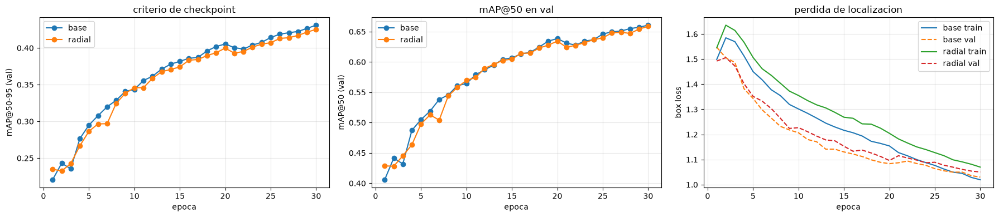

In [47]:
# curvas de entrenamiento (results.csv de ultralytics)
fig, axs = plt.subplots(1, 3, figsize=(18, 4))
for v in VARIANTES:
    csv = Path(PESOS[v]).parents[1] / "results.csv"
    if not csv.is_file():
        print(f"sin results.csv para {v}")
        continue
    df = pd.read_csv(csv)
    df.columns = df.columns.str.strip()
    axs[0].plot(df["epoch"], df["metrics/mAP50-95(B)"], marker="o", label=v)
    axs[1].plot(df["epoch"], df["metrics/mAP50(B)"], marker="o", label=v)
    axs[2].plot(df["epoch"], df["train/box_loss"], label=f"{v} train")
    axs[2].plot(df["epoch"], df["val/box_loss"], "--", label=f"{v} val")
axs[0].set(xlabel="epoca", ylabel="mAP@50-95 (val)", title="criterio de checkpoint")
axs[1].set(xlabel="epoca", ylabel="mAP@50 (val)", title="mAP@50 en val")
axs[2].set(xlabel="epoca", ylabel="box loss", title="perdida de localizacion")
for a in axs:
    a.grid(alpha=0.3)
    a.legend()
plt.tight_layout()
plt.savefig(SALIDAS / "curvas_entrenamiento.png", dpi=150)
plt.show()

Observaciones de las curvas:
* Las dos variantes entrenaron las 30 épocas completas: `base` en la Mac (M4 Max, MPS, 3,4 h) y `radial` en Colab (A100, alrededor de 1 minuto por época).
* En las dos, la mejor época en validación es la última (mAP@50-95 según Ultralytics: 0.431 en `base` y 0.425 en `radial`). El mAP seguía subiendo, así que con más épocas probablemente se ganaba algo más; 30 fue el presupuesto acordado con la rama 4.
* Esos son los números que calcula Ultralytics mientras entrena (umbral 0.001 y su propio evaluador). Más abajo uso las funciones de la rama 2, por eso los valores difieren en milésimas.

Ultralytics guarda los primeros batches de entrenamiento ya augmentados (mosaicos de cuatro imágenes). Sirven para chequear que las cajas caen sobre los objetos, o sea que las etiquetas se cargaron bien. Si la extensión está activada, en `radial` tienen que verse tiles más y menos deformados que en `base`.

base


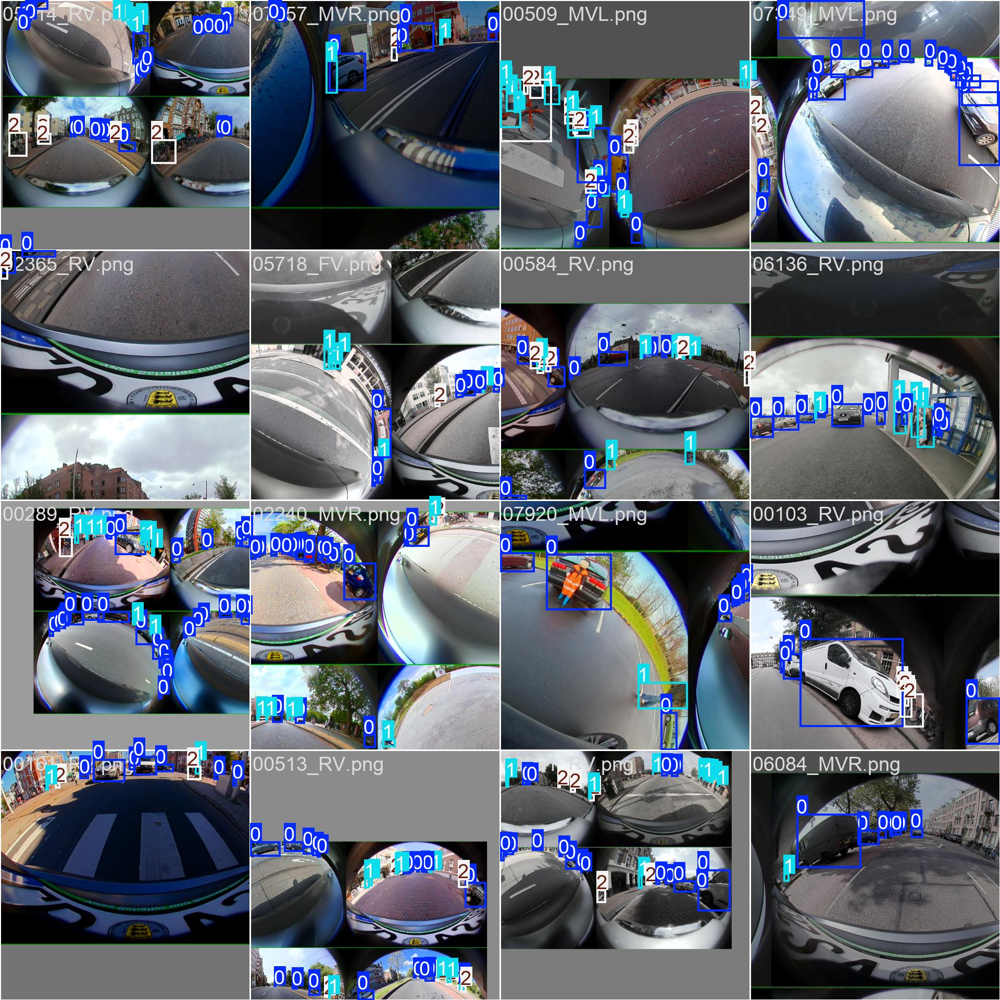

radial


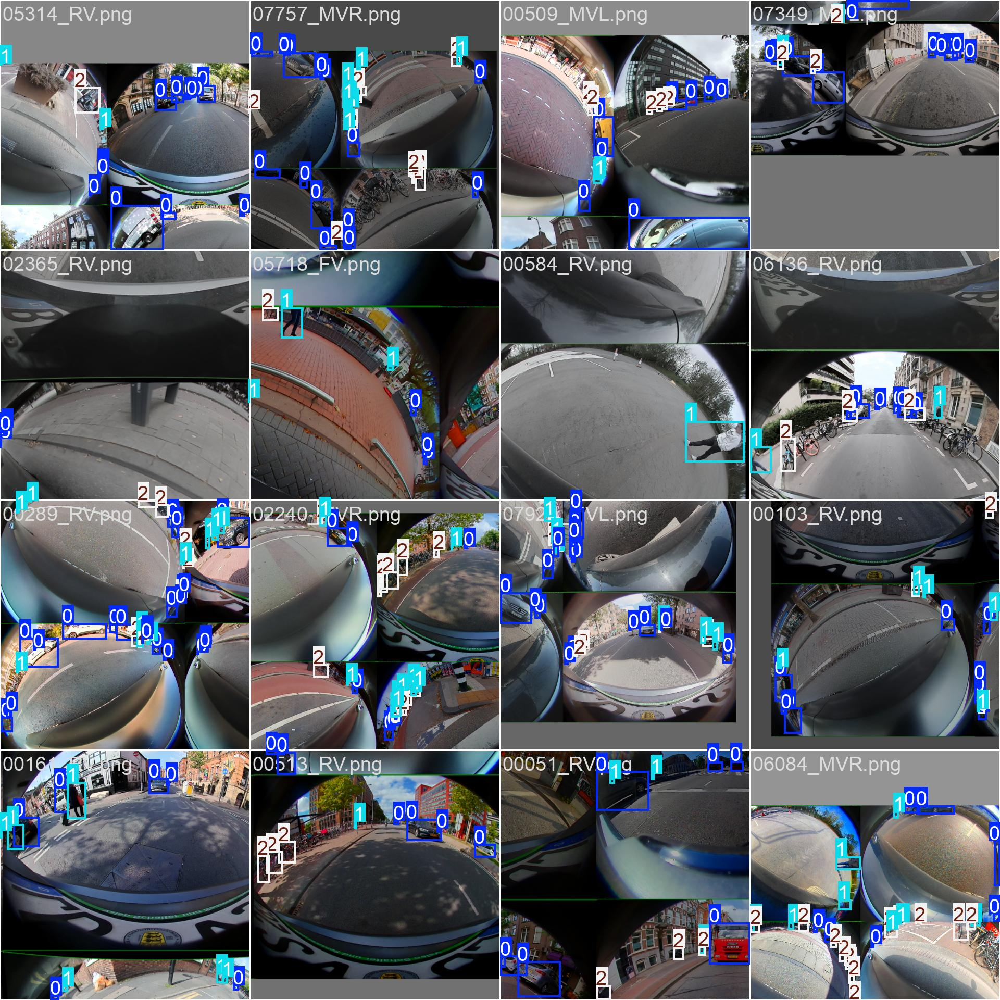

In [48]:
for v in VARIANTES:
    f = Path(PESOS[v]).parents[1] / "train_batch0.jpg"
    if f.is_file():
        print(v)
        display(Image(filename=str(f), width=900))

### Validación

Durante el desarrollo evalúo sobre validación (1085 imágenes, 13.176 cajas), con las mismas funciones que la rama 2:
* `yolo11m_coco`: YOLO11m de COCO sin fine-tuning y con las clases traducidas. Es lo que hace la rama 1; lo recalculo acá como referencia para medir cuánto aporta el fine-tuning, y sirve de control cruzado con los números de la rama 1.
* `rama3_base`: el modelo fine-tuneado (punto C), que ya devuelve las tres clases del TP.
* `rama3_radial`, solo si la extensión está activada.

Guardo las predicciones con confianza ≥ 0.001 y para medir las filtro a 0.01 (`CONF` de `fisheye_utils`), igual que la rama 2. La latencia es por imagen, con diez pasadas de calentamiento, e incluye el resize, el NMS y la copia a CPU. A diferencia de la rama 2, acá no hay pre ni post-procesamiento: la imagen entra tal cual al detector.

Los anillos son los de la rama 2: distancia del centro de la caja al centro óptico, normalizada por la media diagonal, cortada en tercios.

In [49]:
def firma(peso):
    # identifica unos pesos por ruta, tamano y fecha, asi el cache de predicciones no mezcla corridas
    s = Path(peso).stat()
    return hashlib.md5(f"{Path(peso).resolve()}|{s.st_size}|{s.st_mtime}".encode()).hexdigest()[:8]


def detector_ft(peso, conf=CONF_PRED):
    # (detectar, None) para un yolo fine-tuneado: ya devuelve las clases del tp, no hay que traducir
    modelo = YOLO(str(peso))

    def detectar(img):
        r = modelo.predict(img, imgsz=IMGSZ, conf=conf, device=DEVICE, verbose=False)[0].boxes
        return r.xyxy.cpu().numpy(), r.conf.cpu().numpy(), r.cls.cpu().numpy().astype(int)
    return detectar, None


DETECTORES = {"yolo11m_coco": ((lambda: detector_yolo(MODELO_BASE, conf=CONF_PRED)), "coco")}
for v in VARIANTES:
    if Path(PESOS[v]).is_file():
        DETECTORES[f"rama3_{v}"] = ((lambda v=v: detector_ft(PESOS[v])), firma(PESOS[v]))
    else:
        print(f"sin pesos para {v}, no lo evaluo")
print(f"detectores: {list(DETECTORES)}")


def predecir(nombre, filas, split, k=None):
    # corre un detector sobre filas; con k distorsiona cada imagen antes (curva de robustez)
    fabrica, clave = DETECTORES[nombre]
    sufijo = "" if k is None else f"_k{k:+.2f}"
    ruta = SALIDAS / "preds" / f"{nombre}_{clave}_{split}{sufijo}_{len(filas)}.pkl"
    if ruta.exists():
        return pd.read_pickle(ruta)
    ruta.parent.mkdir(exist_ok=True)
    detectar, coco = fabrica()
    img0 = cv2.imread(str(filas.iloc[0].ruta))
    for _ in range(10):  # la primera inferencia en mps compila kernels
        detectar(img0)

    salida = []
    for fila in tqdm(filas.itertuples(), total=len(filas), desc=f"{nombre} {split}{sufijo}"):
        img = cv2.imread(str(fila.ruta))
        if k is not None:
            img, _, _ = distorsionar(img, np.zeros((0, 4)), k, centro=(fila.cx0, fila.cy0))
        t0 = time.perf_counter()
        xyxy, conf, cls = detectar(img)
        t1 = time.perf_counter()
        if coco is not None:
            xyxy, conf, cls = a_clases_tp(xyxy, conf, cls, coco)
        salida.append({"stem": fila.stem, "cajas": xyxy, "conf": conf, "clases": cls, "ms_inf": 1e3 * (t1 - t0)})
    p = pd.DataFrame(salida)
    p.to_pickle(ruta)
    return p


def con_conf(p, umbral=CONF):
    # filtra por confianza; las predicciones se guardan con CONF_PRED y se miden con CONF, como en la rama 2
    q = p.copy()
    m = [c >= umbral for c in q["conf"]]
    for col in ("cajas", "conf", "clases"):
        q[col] = [a[mm] for a, mm in zip(q[col], m)]
    return q

detectores: ['yolo11m_coco', 'rama3_base', 'rama3_radial']


In [50]:
# chequeo: el gt como prediccion tiene que dar 1 tambien en val
gt_como_pred = pd.DataFrame({"stem": val["stem"], "cajas": val["gt_cajas"], "clases": val["gt_clases"],
                             "conf": [np.ones(len(c), dtype=np.float32) for c in val["gt_clases"]]})
m50, m5095 = evaluar(gt_como_pred, val)
assert m50 > 0.99 and m5095 > 0.99, (m50, m5095)

preds_val = {n: con_conf(predecir(n, val, "val")) for n in DETECTORES}
res_val = tabla_resultados(preds_val, val)
res_val.to_csv(SALIDAS / "resultados_val.csv")
res_val.round(3)

,mAP50,mAP50-95,mAP50 centro,mAP50-95 centro,mAP50 medio,mAP50-95 medio,mAP50 periferia,mAP50-95 periferia,ms_inf,ms_total,fps
modelo,,,,,,,,,,,
yolo11m_coco,0.375,0.238,0.531,0.337,0.442,0.288,0.138,0.079,17.842,17.842,56.046
rama3_base,0.652,0.428,0.681,0.431,0.660,0.447,0.567,0.351,17.226,17.226,58.053
rama3_radial,0.652,0.424,0.677,0.427,0.657,0.442,0.575,0.353,16.997,16.997,58.834


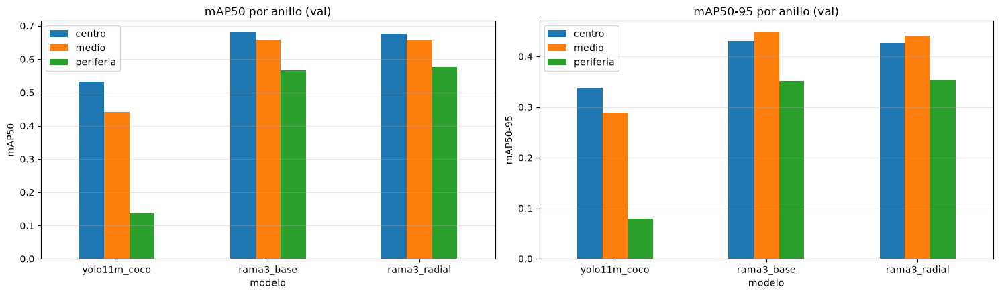

,mAP50 caida c->p,mAP50 delta centro,mAP50 delta periferia,mAP50-95 caida c->p,mAP50-95 delta centro,mAP50-95 delta periferia
modelo,,,,,,
yolo11m_coco,0.741,0.000,0.000,0.765,0.000,0.000
rama3_base,0.167,0.149,0.429,0.186,0.094,0.272
rama3_radial,0.149,0.145,0.438,0.173,0.090,0.274


In [51]:
def resumen_anillos(res, ref="yolo11m_coco"):
    # caida relativa centro -> periferia de cada modelo y cuanto sube cada anillo respecto del modelo sin fine-tuning
    t = pd.DataFrame(index=res.index)
    for m in ("mAP50", "mAP50-95"):
        c, pf = res[f"{m} centro"], res[f"{m} periferia"]
        t[f"{m} caida c->p"] = 1 - pf / c
        if ref in res.index:
            t[f"{m} delta centro"] = c - c[ref]
            t[f"{m} delta periferia"] = pf - pf[ref]
    return t


fig, axs = plt.subplots(1, 2, figsize=(15, 4.5))
for a, m in zip(axs, ("mAP50", "mAP50-95")):
    res_val[[f"{m} {x}" for x in NOMBRES_ANILLOS]].plot.bar(ax=a, rot=0)
    a.set(ylabel=m, title=f"{m} por anillo (val)")
    a.legend(NOMBRES_ANILLOS)
    a.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.savefig(SALIDAS / "anillos_val.png", dpi=150)
plt.show()

resumen_anillos(res_val).round(3)

#### Lectura de la tabla de validación

| | mAP@50 | mAP@50-95 | mAP@50 centro | mAP@50 medio | mAP@50 periferia | caída centro → periferia |
|---|---|---|---|---|---|---|
| YOLO11m COCO (= rama 1) | 0.375 | 0.238 | 0.531 | 0.442 | 0.138 | 74% |
| `rama3_base` (punto C) | **0.652** | **0.428** | 0.681 | 0.660 | **0.567** | **17%** |
| `rama3_radial` (extensión) | 0.652 | 0.424 | 0.677 | 0.657 | 0.575 | 15% |

* El fine-tuning casi duplica el mAP global: de 0.375 a 0.652 en mAP@50 y de 0.238 a 0.428 en mAP@50-95.
* La mejora no es pareja. En el centro el mAP@50 sube 0.15 y en la periferia sube 0.43, o sea que se multiplica por 4. Es justo la zona donde el modelo de COCO fallaba.
* La caída del centro a la periferia pasa del 74% al 17%. Entrenando sobre las fisheye, sin rectificar, el modelo casi empareja los bordes con el centro: aprende las formas deformadas como una apariencia más de cada clase.
* Con mAP@50-95, que además exige cajas bien ubicadas, pasa lo mismo: la periferia sube de 0.079 a 0.351.
* La latencia no cambia (unos 17 ms por imagen en la M4 Max): es el mismo detector y no hay pre ni post-procesamiento.

#### Por cámara y por clase

Las laterales (MVL, MVR) miran hacia abajo y tienen casi todo en la periferia; la frontal y la trasera tienen la calle en el centro. Separo el mAP@50 por cámara como en la rama 2, y el AP@50 por clase para ver si alguna se beneficia más del fine-tuning (`two_wheeler` era la más baja en el baseline).

In [52]:
def solo_clase(p, filas, c):
    # predicciones y gt de una sola clase: el map de eso es el ap de la clase
    q, f = p.copy(), filas.copy()
    m = [k == c for k in q["clases"]]
    for col in ("cajas", "conf", "clases"):
        q[col] = [a[mm] for a, mm in zip(q[col], m)]
    mg = [k == c for k in f["gt_clases"]]
    f["gt_cajas"] = [a[mm] for a, mm in zip(f["gt_cajas"], mg)]
    f["gt_clases"] = [a[mm] for a, mm in zip(f["gt_clases"], mg)]
    return q, f


camaras = sorted(val["camera"].unique())
por_cam = pd.DataFrame({n: {cam: evaluar(p, val[val["camera"] == cam])[0] for cam in camaras} for n, p in preds_val.items()}).T
por_clase = pd.DataFrame({n: {CLASES[c]: evaluar(*solo_clase(p, val, c))[0] for c in range(len(CLASES))} for n, p in preds_val.items()}).T
display(por_cam.round(3).rename(columns=lambda c: f"mAP50 {c}"))
display(por_clase.round(3).rename(columns=lambda c: f"AP50 {c}"))

,mAP50 FV,mAP50 MVL,mAP50 MVR,mAP50 RV
yolo11m_coco,0.517,0.272,0.255,0.488
rama3_base,0.673,0.620,0.633,0.687
rama3_radial,0.670,0.622,0.637,0.684


,AP50 vehicle,AP50 person,AP50 two_wheeler
yolo11m_coco,0.509,0.426,0.189
rama3_base,0.844,0.593,0.519
rama3_radial,0.847,0.597,0.512


Observaciones:
* Las cámaras laterales (MVL y MVR), que ven casi todo en la periferia, son las que más ganan: el mAP@50 pasa de 0.27 y 0.26 a 0.62 y 0.63. Quedan cerca de la frontal y la trasera (0.67 y 0.69), cuando antes rendían la mitad.
* Por clase, `vehicle` pasa de 0.51 a 0.84, `person` de 0.43 a 0.59 y `two_wheeler` de 0.19 a 0.52. La clase más débil del baseline es la que más mejora en proporción (casi ×3): además de la distorsión, el fine-tuning aprende la agrupación de clases del equipo (bicicletas y motos juntas, el conductor como persona), que el modelo de COCO no conocía.
* `person` es la que menos sube, probablemente porque son objetos chicos y finos, más difíciles de ubicar.

#### Anillos por ángulo de incidencia θ

El README del equipo propone estratificar por ángulo de incidencia θ, con los cortes congelados en `config/rings.json` (68,3° y 80,7°, los terciles de la distribución). θ es la magnitud física que gobierna la deformación y permite comparar cámaras con calibraciones distintas. Lo calculo para el centro de cada caja invirtiendo el polinomio $\rho(\theta) = k_1\theta + k_2\theta^2 + k_3\theta^3 + k_4\theta^4$ de la calibración de su imagen.

Uso el mismo esquema que `evaluar`: en cada anillo me quedo con las cajas de gt y las predicciones que caen adentro. El evaluador del README, en cambio, marca como *ignore* los objetos de afuera, así que estos números pueden diferir un poco de los de `eval_radial.py`.

In [53]:
CORTES_THETA = json.loads((RAIZ / "config/rings.json").read_text())["cortes"]


def theta(cajas, fila):
    # angulo de incidencia (grados) del centro de cada caja, invirtiendo rho(theta) de la calibracion de la imagen
    i = json.loads(fila.calib)["intrinsic"]
    u = (cajas[:, 0] + cajas[:, 2]) / 2 - fila.cx0
    v = ((cajas[:, 1] + cajas[:, 3]) / 2 - fila.cy0) / i["aspect_ratio"]
    th = np.linspace(0, np.deg2rad(120), 4000)
    rho = i["k1"] * th + i["k2"] * th**2 + i["k3"] * th**3 + i["k4"] * th**4
    return np.rad2deg(np.interp(np.hypot(u, v), rho, th))


def evaluar_por(p, filas, posicion, lo, hi):
    # igual que evaluar de fisheye_utils, pero el anillo lo define posicion(cajas, fila)
    p = p.set_index("stem")
    P, T = [], []
    for fila in filas.itertuples():
        q = p.loc[fila.stem]
        pg, pp = posicion(fila.gt_cajas, fila), posicion(q["cajas"], fila)
        mg, mp = (pg >= lo) & (pg < hi), (pp >= lo) & (pp < hi)
        T.append(sv.Detections(xyxy=fila.gt_cajas[mg], class_id=fila.gt_clases[mg]))
        P.append(sv.Detections(xyxy=q["cajas"][mp].astype(np.float32), class_id=q["clases"][mp],
                               confidence=q["conf"][mp].astype(np.float32)))
    r = MeanAveragePrecision().update(P, T).compute()
    return r.map50, r.map50_95


th_gt = np.concatenate([theta(f.gt_cajas, f) for f in val.itertuples()])
print(f"cortes: {np.round(CORTES_THETA[1:3], 1)} | cajas de val por anillo:",
      pd.cut(th_gt, CORTES_THETA, labels=NOMBRES_ANILLOS, right=False).value_counts().sort_index().to_dict())

res_theta = pd.DataFrame([
    {"modelo": n, **{f"{m} {a}": x for i, a in enumerate(NOMBRES_ANILLOS)
                    for m, x in zip(("mAP50", "mAP50-95"), evaluar_por(p, val, theta, CORTES_THETA[i], CORTES_THETA[i + 1]))}}
    for n, p in preds_val.items()
]).set_index("modelo")
res_theta.to_csv(SALIDAS / "resultados_val_theta.csv")
res_theta.round(3)

cortes: [       68.3        80.7] | cajas de val por anillo: {'centro': 4344, 'medio': 4397, 'periferia': 4435}


,mAP50 centro,mAP50-95 centro,mAP50 medio,mAP50-95 medio,mAP50 periferia,mAP50-95 periferia
modelo,,,,,,
yolo11m_coco,0.536,0.357,0.412,0.262,0.153,0.088
rama3_base,0.687,0.457,0.636,0.433,0.575,0.358
rama3_radial,0.676,0.451,0.638,0.428,0.579,0.358


Observaciones: con los anillos por ángulo de incidencia, que tienen casi la misma cantidad de cajas cada uno (4344 / 4397 / 4435 en val), el resultado es el mismo. La periferia (θ > 80,7°) pasa de 0.153 a 0.575 de mAP@50 y de 0.088 a 0.358 de mAP@50-95. Los números del modelo de COCO están en línea con los de la rama 1 del README (0.532 en el centro y 0.164 en la periferia, en test y con YOLOv8m), lo que confirma que medimos igual que el equipo.

### Visualización

Una imagen de val por cámara: ground truth, YOLO11m de COCO y el modelo fine-tuneado. Uso un umbral de 0.3 solo para que el dibujo se lea; las métricas usan todas las cajas.

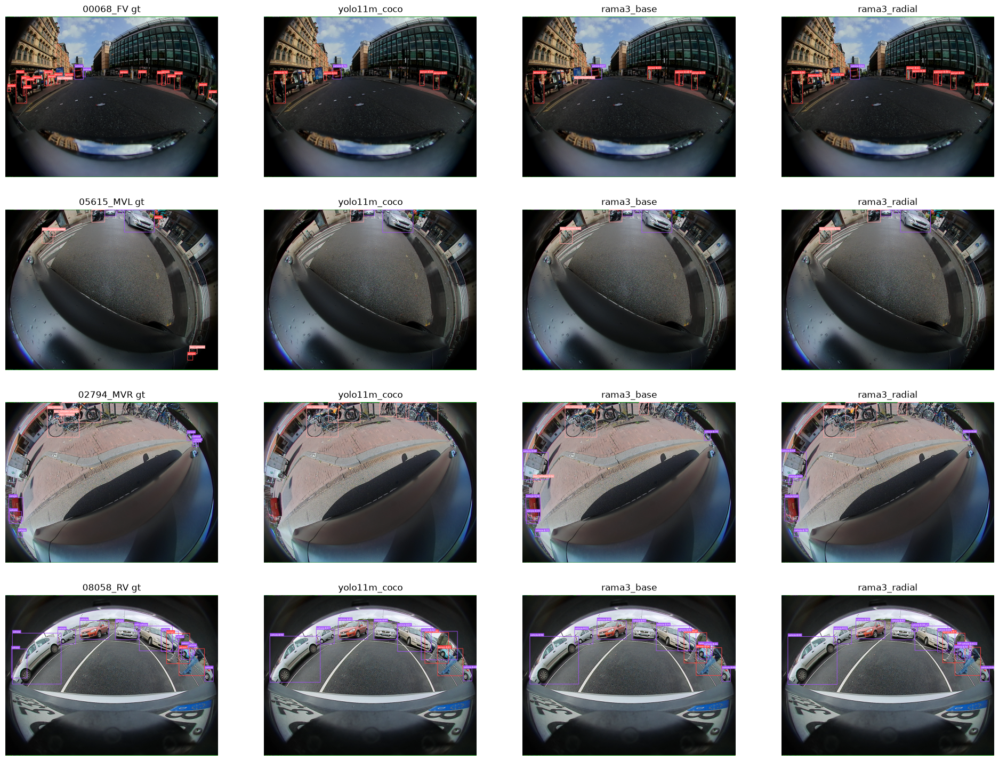

In [54]:
CONF_VIS = 0.3
ejemplos = val.groupby("camera").head(1)
imgs, titulos = [], []
for fila in ejemplos.itertuples():
    img = cv2.imread(str(fila.ruta))
    imgs.append(dibujar(img, fila.gt_cajas, fila.gt_clases))
    titulos.append(f"{fila.stem} gt")
    for n, p in preds_val.items():
        q = p.set_index("stem").loc[fila.stem]
        m = q["conf"] >= CONF_VIS
        imgs.append(dibujar(img, q["cajas"][m], q["clases"][m], q["conf"][m]))
        titulos.append(n)
cols = 1 + len(preds_val)
sv.plot_images_grid(imgs, grid_size=(len(ejemplos), cols), titles=titulos, size=(6 * cols, 18))

### Test (una sola vez)

Solo con los pesos definitivos (los de las 30 épocas) y `EVALUAR_TEST = True`. Uso `cargar_test` de `fisheye_utils`, igual que la rama 2: las 1000 imágenes del Drive (verificadas por sha256) y el mismo ground truth de 11.910 cajas. La latencia de esta corrida es la que va a la tabla, pero para comparar ramas tiene que medirse en la misma máquina para todas.

Además de las tablas, exporto las predicciones como `.txt` de Ultralytics (`clase cx cy w h conf`, normalizado) para poder pasarlas por `eval_radial.py` si el equipo usa ese evaluador.

In [55]:
# rama 2 con yolo11m sobre el mismo test (tabla del notebook de la rama 2); si esta el csv, lo leo de ahi
RAMA2_CSV = RAIZ / "outputs/rama2/resultados.csv"
if RAMA2_CSV.is_file():
    rama2 = pd.read_csv(RAMA2_CSV, index_col=0).loc[["yolo11m"]].rename(index={"yolo11m": "rama2_cilindrica"})
else:
    rama2 = pd.DataFrame([{
        "mAP50": 0.418, "mAP50-95": 0.155, "mAP50 centro": 0.560, "mAP50-95 centro": 0.299,
        "mAP50 medio": 0.419, "mAP50-95 medio": 0.143, "mAP50 periferia": 0.292, "mAP50-95 periferia": 0.100,
        "ms_total": 40.322,
    }], index=pd.Index(["rama2_cilindrica"], name="modelo"))


def exportar_txt(p, filas, carpeta):
    # predicciones como labels de ultralytics con confianza (save_txt + save_conf), para eval_radial.py
    carpeta.mkdir(parents=True, exist_ok=True)
    p = p.set_index("stem")
    for fila in filas.itertuples():
        q = p.loc[fila.stem]
        c = q["cajas"]
        lineas = [f"{k} {(x1 + x2) / 2 / fila.W:.6f} {(y1 + y2) / 2 / fila.H:.6f} {(x2 - x1) / fila.W:.6f} {(y2 - y1) / fila.H:.6f} {s:.5f}"
                  for (x1, y1, x2, y2), k, s in zip(c, q["clases"], q["conf"])]
        (carpeta / f"{fila.stem}.txt").write_text("\n".join(lineas) + ("\n" if lineas else ""))


if EVALUAR_TEST:
    test = cargar_test()
    preds_test_crudas = {n: predecir(n, test, "test") for n in DETECTORES}
    preds_test = {n: con_conf(p) for n, p in preds_test_crudas.items()}
    res_test = tabla_resultados(preds_test, test)
    res_test.to_csv(SALIDAS / "resultados_test.csv")
    for n, p in preds_test_crudas.items():
        exportar_txt(p, test, SALIDAS / "pred_txt" / n)

    comparacion = pd.concat([res_test, rama2])[[c for c in res_test.columns if c.startswith("mAP")] + ["ms_total"]]
    comparacion = comparacion.rename(index={"yolo11m_coco": "rama1_baseline (recalculado)"})
    comparacion.to_csv(SALIDAS / "comparacion_test.csv")
    display(comparacion.round(3))
    display(resumen_anillos(res_test).round(3))
else:
    print("test sin correr: poner EVALUAR_TEST = True solo con los pesos definitivos")

test: 1000 imagenes en el manifest | presentes: 1000 | faltan 0


,mAP50,mAP50-95,mAP50 centro,mAP50-95 centro,mAP50 medio,mAP50-95 medio,mAP50 periferia,mAP50-95 periferia,ms_total
modelo,,,,,,,,,
rama1_baseline (recalculado),0.378,0.239,0.527,0.342,0.445,0.285,0.144,0.083,16.982
rama3_base,0.659,0.430,0.685,0.439,0.660,0.444,0.596,0.367,17.424
rama3_radial,0.656,0.426,0.680,0.428,0.658,0.442,0.594,0.364,17.568
rama2_cilindrica,0.418,0.155,0.560,0.299,0.419,0.143,0.292,0.100,40.322


,mAP50 caida c->p,mAP50 delta centro,mAP50 delta periferia,mAP50-95 caida c->p,mAP50-95 delta centro,mAP50-95 delta periferia
modelo,,,,,,
yolo11m_coco,0.727,0.000,0.000,0.757,0.000,0.000
rama3_base,0.130,0.158,0.452,0.163,0.096,0.284
rama3_radial,0.125,0.153,0.451,0.151,0.086,0.280


### Conclusiones

Las conclusiones 1 a 5 usan validación (1085 imágenes, 13.176 cajas). Las 6 a 8 usan el test (1000 imágenes, 11.910 cajas), que se corrió una sola vez con los pesos finales.

1. **El fine-tuning sin rectificar casi duplica el desempeño.** El mAP@50 global sube de 0.375 a 0.652 y el mAP@50-95 de 0.238 a 0.428, con el mismo modelo (YOLO11m), la misma resolución y la misma latencia.
2. **La mejora se concentra en la periferia, que es el problema del trabajo.** En el centro el mAP@50 sube 0.15 (0.531 → 0.681) y en la periferia 0.43 (0.138 → 0.567). La caída del centro a la periferia baja del 74% al 17%. Medido por ángulo de incidencia θ da lo mismo: la periferia pasa de 0.153 a 0.575.
3. **Lo más débil es lo que más mejora.** Las cámaras laterales más que duplican su mAP@50 (0.27 → 0.62 y 0.26 → 0.63) y `two_wheeler` casi lo triplica (0.19 → 0.52).
4. **No hay costo en el auto.** La latencia es la del detector solo, unos 17 ms por imagen en la M4 Max, sin remap ni reproyección de cajas. Para una ECU es la opción más simple: el mismo modelo con otros pesos.
5. **La augmentación de distorsión radial (extensión) no mejora en estas cámaras, pero hace al modelo más robusto a otras lentes.** Con las imágenes del dataset, `radial` y `base` rinden igual (diferencias menores a un punto). Cuando se agrega distorsión, `base` pierde hasta 0.06 de mAP@50-95 y `radial` la mitad, unos 0.03. Sirve si el modelo se va a usar con cámaras distintas a las de entrenamiento.
6. **Contra la rama 2 (rectificar sin entrenar), en test.** Con el mismo YOLO11m, rectificar sin entrenar lleva la periferia de 0.144 a 0.292 de mAP@50; entrenar sin rectificar la lleva a 0.596, el doble que la rama 2. En el global la rama 2 queda en 0.418 de mAP@50 y 0.155 de mAP@50-95 (por debajo de la rama 1 en mAP@50-95, por la reproyección de las cajas), contra 0.659 y 0.430 de esta rama. Además deja fuera de la banda cilíndrica el 4,3% de las cajas y agrega preprocesamiento en el auto.
7. **Contra la rama 4 (rectificar y entrenar), en test.** Una vez que el modelo se entrena, rectificar resta. La rama 4 queda en 0.521 de mAP@50 global y 0.389 en la periferia, contra 0.659 y 0.596 de esta rama; en mAP@50-95, 0.172 contra 0.430. No es que la rama 4 entrene peor: en su propia validación cilíndrica llega a 0.446 de mAP@50-95, a la par del 0.431 de esta rama en la fisheye (los dos según Ultralytics). Lo pierde al volver a la fisheye: aun con una detección perfecta, la caja reproyectada tiene IoU mediana 0.65 en el anillo medio y la periferia, y el 3,4% de los objetos queda fuera de la banda.

Con las cuatro ramas se puede estimar el diseño 2×2. Es mAP@50 en test con YOLO11m, anillos por radio, todas medidas con `tabla_resultados`:

| efecto | global | periferia |
|---|---|---|
| rectificar sin fine-tuning (rama 2 − rama 1) | +0.040 | +0.148 |
| rectificar con fine-tuning (rama 4 − rama 3) | −0.138 | −0.207 |
| fine-tuning sin rectificar (rama 3 − rama 1) | +0.281 | +0.452 |
| fine-tuning con rectificar (rama 4 − rama 2) | +0.103 | +0.097 |
| **interacción** (4 − 3) − (2 − 1) | **−0.178** | **−0.355** |

La hipótesis del equipo era que rectificar aporta menos cuando el modelo ya vio datos fisheye. Los datos dicen algo más fuerte: rectificar ayuda al detector sin entrenar y perjudica al entrenado, y el fine-tuning es el factor que más pesa. Por ángulo θ, con las cuatro ramas corridas en la misma máquina y medidas con el mismo evaluador (`notebooks/comparacion_2x2.ipynb`), da lo mismo: interacción de −0.178 en el global y −0.339 en la periferia.

8. **No hacen falta más épocas.** Las 30 épocas alcanzan para responder la pregunta del trabajo:
   * **Rendimientos decrecientes.** El mAP@50-95 de validación de `base` sube 0.12 en las épocas 1–10, 0.06 en las 11–20 y 0.026 en las 21–30, unas 0.003 por época al final. `radial` sigue el mismo patrón.
   * **La subida final es el afinado del programa de entrenamiento, no una tendencia.** En las últimas 10 épocas se apaga el mosaico y la tasa de aprendizaje baja casi a cero (0.00006 en la época 30). Que la mejor época sea la última es lo esperable con ese programa, no una señal de que el modelo siga mejorando al mismo ritmo.
   * **No hay sobreajuste y el modelo generaliza.** Las pérdidas de entrenamiento y de validación bajan juntas (box loss 1.02 y 1.03 al final) y el test da lo mismo que validación (mAP@50 0.659 contra 0.652).
   * **Lo que falta es chico frente a lo que ya se ganó.** Extrapolando las curvas, más épocas sumarían del orden de 0.01 a 0.03 de mAP@50-95. El fine-tuning ya aporta 0.19 en test (0.239 → 0.430) y multiplica por 4 la periferia (0.144 → 0.596): ninguna conclusión cambiaría.
   * **Comparabilidad y costo.** 30 épocas es el presupuesto común con la rama 4; entrenar más solo esta rama mezclaría el efecto de rectificar con el de entrenar más. Además habría que reentrenar desde cero, porque el programa de entrenamiento ya terminó: unas 11 horas por variante en la Mac para 100 épocas.

**Limitaciones:**
* 30 épocas: la mejor época fue la última en las dos variantes, pero por lo visto en la conclusión 8 más entrenamiento daría una mejora marginal.
* `base` se entrenó en la Mac (MPS, precisión simple) y `radial` en Colab (A100, precisión mixta). Las diferencias chicas entre las dos variantes hay que tomarlas con cuidado.
* Los anillos por θ usan el mismo esquema de filtrado que la rama 2, no el *ignore* del evaluador del README, así que pueden diferir algunas milésimas de `eval_radial.py`.
* La latencia de las cuatro ramas en la misma máquina está en `notebooks/comparacion_2x2.ipynb`: la rectificación suma unos 3 ms por imagen y el fine-tuning nada. Los valores absolutos varían entre sesiones (17 ms acá, 23 ms en esa corrida, con el mismo modelo).
* La comparación con la rama 4 tiene dos diferencias de entrenamiento menores (batch físico 16 contra 2 y semilla 0 contra 42; el batch nominal, el optimizador y el lr son los mismos) y una sola corrida por rama. La brecha en test (0.14 de mAP@50 global) es mucho mayor que las diferencias del orden de 0.01–0.02 que se le pueden atribuir a eso.

### Preguntas para la defensa

**¿Por qué no rectificar la imagen?** Esa es la rama 2. La rama 3 prueba si el modelo puede aprender la deformación por sí solo, sin costo extra en el auto: no hay preprocesamiento y la latencia es la del detector.

**¿Por qué la rama 4 rinde menos si también entrena?** Entrena igual de bien (0.446 de mAP@50-95 en su validación cilíndrica contra 0.431 de esta rama), pero detecta en la cilíndrica y tiene que llevar las cajas de vuelta a la fisheye. Una caja recta en la cilíndrica es un contorno curvo en la fisheye, y la caja que lo encierra es más grande que el objeto: aun con una detección perfecta, la IoU mediana es 0.65 en la periferia. Eso castiga sobre todo el mAP@50-95. Además, los objetos fuera de la banda no se pueden detectar. Si el modelo ya aprende la deformación, rectificar solo agrega esas pérdidas.

**¿Cómo aprende la periferia si la convolución usa el mismo filtro en toda la imagen?** La convolución es equivariante a traslaciones: no puede tener filtros especiales para el borde. Lo que hace el fine-tuning es agregar al repertorio de cada clase sus versiones deformadas (un peatón curvado e inclinado pasa a ser otra forma posible de peatón). El mosaico ayuda, porque lleva objetos deformados de la periferia a otras posiciones de la imagen.

**¿Por qué YOLO11m?** Es el que eligió la rama 2: está en el codo de precisión contra latencia (unos 25 FPS en su Mac) y es el tipo de detector de una etapa que correría en una ECU. Todas las ramas usan el mismo.

**¿Por qué partir de COCO y no entrenar de cero?** COCO ya sabe qué es un auto o una persona; solo le falta ver cómo se deforman. Con 6148 imágenes, entrenar de cero rendiría mucho menos.

**¿Por qué no congelaron capas?** La deformación cambia las formas desde los rasgos más básicos, así que conviene ajustar toda la red. Con 75.000 cajas hay datos suficientes para hacerlo sin sobreajustar.

**¿Por qué 30 épocas?** Es el presupuesto común con la rama 4, que también entrena, y lo que entraba en el tiempo disponible. Las dos variantes seguían mejorando al final, así que el resultado es una cota inferior de lo que da el fine-tuning.

**¿Cómo eligieron el modelo final?** La época con mejor mAP@50-95 en validación, el mismo criterio en todas las ramas. El test no se usó para elegir nada.

**¿El test es justo?** Sí: 1000 imágenes estratificadas por cámara, auditadas contra casi-duplicados del train (una imagen quedó en cuarentena), verificadas por sha256 y usadas una sola vez.

**¿Por qué la augmentación radial no mejora en validación?** Porque validación y test tienen las mismas cámaras que train, y el fine-tuning ya aprende esa distorsión. La augmentación sirve cuando la distorsión cambia, que es lo que muestra la curva de robustez.

**¿La comparación entre `base` y `radial` es justa?** Los parámetros son idénticos, pero se entrenaron en plataformas distintas (Mac y Colab). Las diferencias en validación (menos de un punto) no se pueden atribuir a la augmentación. La diferencia en robustez es más grande (unos 0.03 de mAP@50-95 en los extremos) y está a favor de `radial` en todos los k distintos de 0.

## Extensión: augmentación de distorsión radial (fuera del punto C)

Esta parte queda preparada para después. Es la tercera estrategia de la propuesta original y la que recomendó el profesor: fine-tuning con augmentaciones que simulen distintos grados de distorsión radial, manteniendo las mismas cajas y las mismas clases.

Se activa agregando `"radial"` a `VARIANTES` en la configuración y volviendo a correr el notebook: se entrena `rama3_radial` con exactamente los mismos parámetros que `base`, aparece en las tablas de validación y test, y se corren las celdas de abajo. La diferencia `radial` − `base` mide el efecto de la augmentación. Una salvedad para el paper: `base` se entrenó en la Mac (MPS, precisión simple) y `radial` en Colab (GPU NVIDIA, precisión mixta), con los mismos parámetros. Esa diferencia de plataforma puede mover algunas décimas el resultado; si la diferencia entre las dos variantes es chica, hay que tomarla con cuidado o repetir `base` en Colab. Con la extensión desactivada, estas celdas no hacen nada.

### Augmentación de distorsión radial

El fine-tuning sobre WoodScape ya le muestra al modelo la distorsión de estas cámaras, pero siempre la misma: cada objeto aparece con la deformación que le toca según su posición. La augmentación simula lentes con más y con menos distorsión, así el mismo objeto aparece con distintos grados de deformación durante el entrenamiento.

Para cada píxel de salida a distancia normalizada $r$ del centro óptico ($r = 1$ en la esquina más lejana) leo el píxel de entrada que está a

$$r_{src} = r\,\frac{1 + k\,r^2}{1 + k}$$

* $k = 0$ deja la imagen igual.
* $k > 0$ agranda el centro y comprime la periferia, como una lente más fisheye. Con $k = 0.3$ el centro se agranda 1,3× y la esquina se comprime a 0,68×.
* $k < 0$ hace lo contrario y se acerca a una rectificación parcial. Con $k = -0.2$ el centro queda en 0,8× y la esquina se estira 2×.
* El aumento local es $(1 + k) / (1 + 3 k r^2)$, así que la transformación es monótona mientras $k > -1/3$.
* La esquina más lejana queda fija: no aparecen bordes negros nuevos (salvo una fracción de píxel en las otras esquinas, porque el centro óptico está corrido unos 4 px del geométrico).

En cada imagen de entrenamiento, con probabilidad $p = 0.5$, sorteo $k \sim U[-0.2,\ 0.3]$. La otra mitad queda como está, que es la distribución de validación y test. El rango es asimétrico porque con $k$ negativo la periferia se estira rápido.

**Dónde se aplica.** En una subclase de `YOLODataset` que redefine `update_labels_info`, el último paso de `get_image_and_label`. A ese método lo llama `__getitem__` y también el mosaico para las otras tres imágenes, así que cada imagen se distorsiona alrededor de su propio centro óptico (de `config/calibration.json`) antes de armar el mosaico. Como está en el dataset y no en la lista de transforms, sigue activa en las últimas épocas, cuando Ultralytics apaga el mosaico. Solo actúa en train.

**Cajas.** Muestreo 16 puntos por lado de cada caja, los llevo a la imagen distorsionada invirtiendo $r_{src}(r)$ con una tabla y me quedo con el mínimo y el máximo, el mismo criterio que `caja_a_fisheye` de la rama 2. Tiene la misma limitación: la caja que encierra un rectángulo deformado es algo más grande que la del objeto deformado. Con estas intensidades el efecto es chico. Con los polígonos de las anotaciones sería exacto, pero eso cambiaría cómo se calculan todas las cajas de entrenamiento y lo dejo afuera para no mezclar modificaciones.

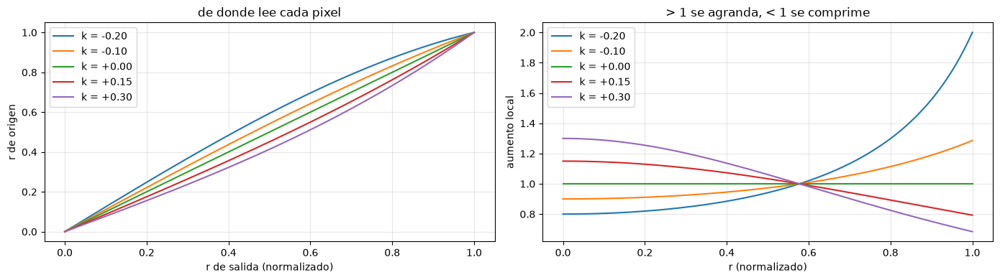

In [56]:
if EXTENSION_RADIAL:
    r = np.linspace(0, 1, 200)
    fig, axs = plt.subplots(1, 2, figsize=(14, 4))
    for k in [-0.2, -0.1, 0.0, 0.15, 0.3]:
        axs[0].plot(r, r * (1 + k * r**2) / (1 + k), label=f"k = {k:+.2f}")
        axs[1].plot(r, (1 + k) / (1 + 3 * k * r**2), label=f"k = {k:+.2f}")
    axs[0].set(xlabel="r de salida (normalizado)", ylabel="r de origen", title="de donde lee cada pixel")
    axs[1].set(xlabel="r (normalizado)", ylabel="aumento local", title="> 1 se agranda, < 1 se comprime")
    for a in axs:
        a.grid(alpha=0.3)
        a.legend()
    plt.tight_layout()
    plt.savefig(SALIDAS / "aug_radial_curvas.png", dpi=150)
    plt.show()
else:
    print("extension desactivada: agregar 'radial' a VARIANTES en la configuracion")

In [57]:
if EXTENSION_RADIAL:
    # chequeos de la transformacion antes de entrenar con ella
    h, w = 483, 640  # tamano de las imagenes ya redimensionadas a imgsz
    cx, cy = 323.0, 238.5  # un centro corrido del geometrico, como el optico
    u, v = np.meshgrid(np.arange(w), np.arange(h))

    # 1. con k = 0 la imagen no puede cambiar
    mx, my = mapas_radiales(w, h, 0.0, cx, cy)
    assert np.allclose(mx, u, atol=1e-3) and np.allclose(my, v, atol=1e-3), "con k = 0 los mapas tienen que ser la identidad"

    # 2. ida y vuelta: llevo puntos a la distorsionada con puntos_adelante y vuelvo leyendo los mapas en esa posicion
    rng = np.random.default_rng(0)
    R = radio_max(w, h, cx, cy)
    for k in (-0.2, 0.15, 0.3):
        x, y = rng.uniform(0, w - 1, 2000), rng.uniform(0, h - 1, 2000)
        xd, yd = puntos_adelante(x, y, k, cx, cy, R)
        dentro = (xd >= 0) & (xd <= w - 1) & (yd >= 0) & (yd <= h - 1)
        mx, my = mapas_radiales(w, h, k, cx, cy)
        xv = cv2.remap(mx, xd[dentro].astype(np.float32)[None], yd[dentro].astype(np.float32)[None], cv2.INTER_LINEAR)[0]
        yv = cv2.remap(my, xd[dentro].astype(np.float32)[None], yd[dentro].astype(np.float32)[None], cv2.INTER_LINEAR)[0]
        err = np.hypot(xv - x[dentro], yv - y[dentro]).max()
        assert err < 0.05, (k, err)
        print(f"k = {k:+.2f}: ida y vuelta, error maximo {err:.4f} px | puntos que quedan dentro de cuadro: {dentro.mean():.1%}")

    # 3. una caja chica alrededor de un punto tiene que contener al punto distorsionado
    caja = np.array([[500, 100, 520, 130]])
    for k in (-0.2, 0.3):
        c, ok = distorsionar_cajas(caja, k, w, h, (cx, cy))
        px, py = puntos_adelante(np.array([510.0]), np.array([115.0]), k, cx, cy, R)
        assert ok[0] and c[0, 0] <= px[0] <= c[0, 2] and c[0, 1] <= py[0] <= c[0, 3], (k, c, px, py)
    print("chequeos ok")
else:
    print("extension desactivada: agregar 'radial' a VARIANTES en la configuracion")

k = -0.20: ida y vuelta, error maximo 0.0005 px | puntos que quedan dentro de cuadro: 100.0%
k = +0.15: ida y vuelta, error maximo 0.0003 px | puntos que quedan dentro de cuadro: 91.1%
k = +0.30: ida y vuelta, error maximo 0.0005 px | puntos que quedan dentro de cuadro: 84.5%
chequeos ok


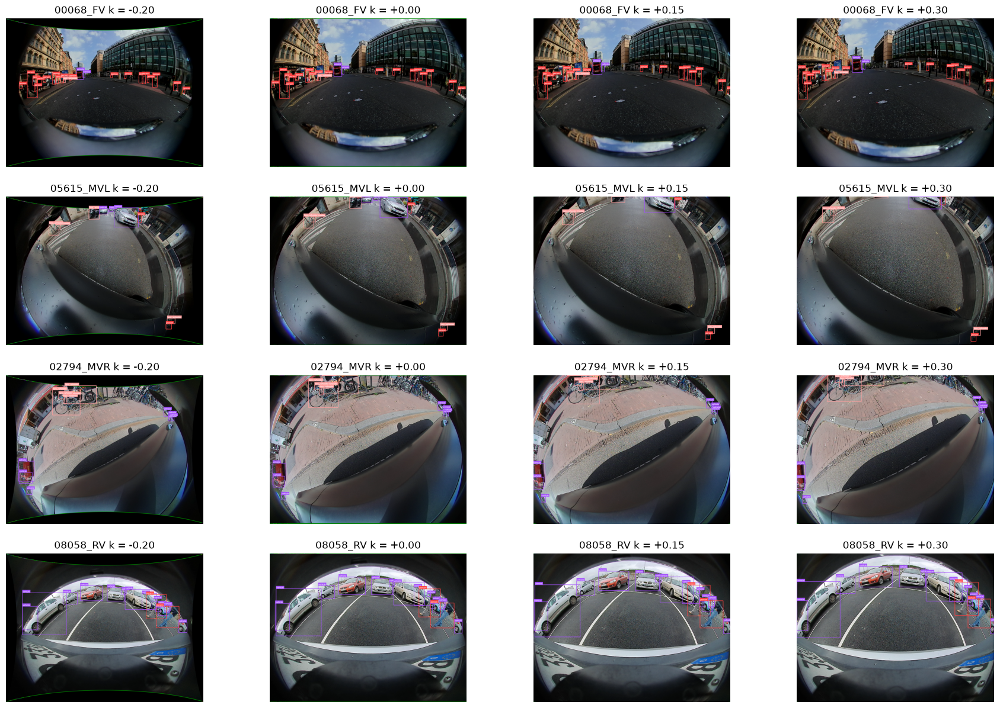

In [58]:
if EXTENSION_RADIAL:
    # una imagen de val por camara con distintos k y su ground truth transformado
    K_VIS = [-0.2, 0.0, 0.15, 0.3]
    ejemplos = val.groupby("camera").head(1)
    imgs, titulos = [], []
    for fila in ejemplos.itertuples():
        img = cv2.imread(str(fila.ruta))
        for k in K_VIS:
            im_k, cajas_k, ok = distorsionar(img, fila.gt_cajas, k, centro=(fila.cx0, fila.cy0))
            imgs.append(dibujar(im_k, cajas_k[ok], fila.gt_clases[ok]))
            titulos.append(f"{fila.stem} k = {k:+.2f}")
    sv.plot_images_grid(imgs, grid_size=(len(ejemplos), len(K_VIS)), titles=titulos, size=(22, 15))
else:
    print("extension desactivada: agregar 'radial' a VARIANTES en la configuracion")

Qué tiene que verse en la grilla:
* La columna `k = +0.00` es la imagen original.
* Con `k > 0` el centro se agranda y lo de los bordes se achica y se curva más. Lo que estaba pegado al borde lateral puede quedar fuera de cuadro.
* Con `k < 0` la periferia se estira y las líneas curvas se enderezan un poco.
* En todos los casos las cajas tienen que seguir encerrando a sus objetos.

### Robustez frente al grado de distorsión

Para ver si la augmentación hace al modelo más robusto a la deformación, distorsiono un subconjunto de validación con varios $k$ (la misma transformación del entrenamiento, alrededor del centro óptico) y evalúo los tres modelos. Las cajas de referencia se transforman igual que en el entrenamiento, así que quedan un poco infladas en los bordes; eso afecta a los tres modelos por igual.

Si la augmentación sirve, la curva de `rama3_radial` tiene que caer menos que la de `rama3_base` al alejarse de $k = 0$.

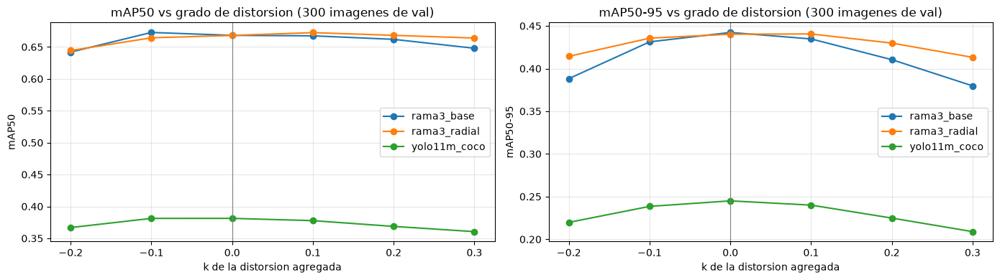

k,-0.2,-0.1,0.0,0.1,0.2,0.3
modelo,,,,,,
rama3_base,0.388,0.431,0.442,0.435,0.410,0.380
rama3_radial,0.414,0.436,0.440,0.441,0.430,0.413
yolo11m_coco,0.220,0.239,0.245,0.240,0.225,0.209


In [59]:
if EXTENSION_RADIAL:
    sub = val.groupby("camera").head(N_ROBUSTEZ // 4).reset_index(drop=True)


    def gt_distorsionado(filas, k):
        # el gt de filas llevado a la imagen distorsionada con k (descarto las cajas que se degeneran)
        f = filas.copy()
        cajas, clases = [], []
        for fila in filas.itertuples():
            c, ok = distorsionar_cajas(fila.gt_cajas, k, int(fila.W), int(fila.H), (fila.cx0, fila.cy0))
            cajas.append(c[ok])
            clases.append(fila.gt_clases[ok])
        f["gt_cajas"], f["gt_clases"] = cajas, clases
        return f


    rob = []
    for k in K_ROBUSTEZ:
        sub_k = sub if k == 0 else gt_distorsionado(sub, k)
        for n in DETECTORES:
            m50, m5095 = evaluar(con_conf(predecir(n, sub, "val", k=None if k == 0 else k)), sub_k)
            rob.append({"modelo": n, "k": k, "mAP50": m50, "mAP50-95": m5095})
    rob = pd.DataFrame(rob)
    rob.to_csv(SALIDAS / "robustez_val.csv", index=False)

    fig, axs = plt.subplots(1, 2, figsize=(14, 4))
    for a, m in zip(axs, ("mAP50", "mAP50-95")):
        for n, d in rob.groupby("modelo"):
            a.plot(d["k"], d[m], marker="o", label=n)
        a.axvline(0, color="gray", lw=0.8)
        a.set(xlabel="k de la distorsion agregada", ylabel=m, title=f"{m} vs grado de distorsion ({len(sub)} imagenes de val)")
        a.grid(alpha=0.3)
        a.legend()
    plt.tight_layout()
    plt.savefig(SALIDAS / "robustez_val.png", dpi=150)
    plt.show()
    display(rob.pivot(index="modelo", columns="k", values="mAP50-95").round(3))
else:
    print("extension desactivada: agregar 'radial' a VARIANTES en la configuracion")

#### Lectura de la robustez

mAP@50-95 sobre 300 imágenes de val, distorsionadas con k alrededor del centro óptico:

| k | −0.2 | −0.1 | 0 | +0.1 | +0.2 | +0.3 |
|---|---|---|---|---|---|---|
| `rama3_base` | 0.388 | 0.431 | 0.442 | 0.435 | 0.410 | 0.380 |
| `rama3_radial` | **0.414** | 0.436 | 0.440 | 0.441 | **0.430** | **0.413** |
| YOLO11m COCO | 0.220 | 0.239 | 0.245 | 0.240 | 0.225 | 0.209 |

* Sin distorsión agregada (k = 0) las dos variantes rinden igual: el fine-tuning ya aprendió la distorsión de estas cámaras.
* Al agregar distorsión, `base` pierde 0.054 (k = −0.2) y 0.062 (k = +0.3); `radial` pierde 0.026 y 0.027, la mitad. `radial` queda por encima en todos los k distintos de 0.
* La augmentación no mejora el rendimiento en las cámaras del dataset, pero hace al modelo más robusto a lentes con más o menos distorsión. Es la estrategia que recomendó el profesor, y su efecto aparece donde tiene sentido: cuando cambia la lente.
* Salvedad: `base` y `radial` se entrenaron en plataformas distintas. La diferencia en robustez (unos 0.03) es mayor que la de validación normal y tiene el mismo signo en todos los k.

## Comparación gráfica del test

Tres gráficas para comparar los modelos sobre las 1000 imágenes de test, con los mismos números de la tabla de arriba (`outputs/rama3/comparacion_test.csv`). Los colores son siempre los mismos para cada modelo, y cada uno tiene además su propia forma de marcador:

* **Rama 3 · fine-tuning (`base`)**: el punto C, azul.
* **Rama 1 · COCO sin entrenar**: la referencia, recalculada con las mismas funciones, naranja.
* **Rama 2 · proyección cilíndrica**: números del notebook de la rama 2 sobre el mismo test, verde agua.
* **Rama 3 · + augmentación radial**: la extensión, amarillo.

Las figuras se guardan en `outputs/rama3/` para el informe.

In [60]:
# estilo comun de las graficas del test: superficie clara, grilla y ejes discretos, texto en tinta (nunca del color de la serie)
SUPERFICIE, TINTA, TINTA2, APAGADO, GRILLA, EJE = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"

comp = pd.read_csv(SALIDAS / "comparacion_test.csv", index_col=0)

# (fila de la tabla, etiqueta, color, marcador): orden fijo de la paleta, el color sigue al modelo en todas las figuras
SERIES = [s for s in [
    ("rama3_base", "Rama 3 · fine-tuning (base)", "#2a78d6", "o"),
    ("rama1_baseline (recalculado)", "Rama 1 · COCO sin entrenar", "#eb6834", "s"),
    ("rama2_cilindrica", "Rama 2 · proyección cilíndrica", "#1baf7a", "D"),
    ("rama3_radial", "Rama 3 · + augmentación radial", "#eda100", "^"),
] if s[0] in comp.index]


def estilo(ax, grilla="y"):
    ax.set_facecolor(SUPERFICIE)
    ax.grid(axis=grilla, color=GRILLA, linewidth=1, linestyle="-")
    ax.set_axisbelow(True)
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
    for lado in ("left", "bottom"):
        ax.spines[lado].set_color(EJE)
    ax.tick_params(colors=EJE, labelcolor=TINTA2)


comp[[c for c in comp.columns if c.startswith("mAP")] + ["ms_total"]].round(3)

,mAP50,mAP50-95,mAP50 centro,mAP50-95 centro,mAP50 medio,mAP50-95 medio,mAP50 periferia,mAP50-95 periferia,ms_total
modelo,,,,,,,,,
rama1_baseline (recalculado),0.378,0.239,0.527,0.342,0.445,0.285,0.144,0.083,16.982
rama3_base,0.659,0.430,0.685,0.439,0.660,0.444,0.596,0.367,17.424
rama3_radial,0.656,0.426,0.680,0.428,0.658,0.442,0.594,0.364,17.568
rama2_cilindrica,0.418,0.155,0.560,0.299,0.419,0.143,0.292,0.100,40.322


### 1. mAP por anillo: ¿cuánto cae cada modelo hacia los bordes?

Cada línea es un modelo; de izquierda a derecha, los objetos están cada vez más lejos del centro de la lente. **Una línea plana significa que el modelo detecta igual de bien en todo el campo de visión; cuanto más cae, más le afecta la distorsión.** El número a la derecha es el valor en la periferia (cuando dos quedan muy juntos se rotula uno solo; los valores exactos están en la tabla de arriba).

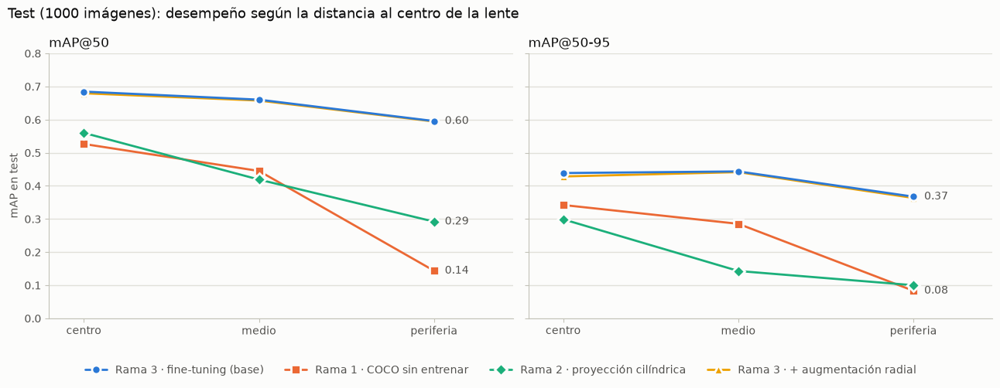

In [61]:
x = np.arange(len(NOMBRES_ANILLOS))
fig, axs = plt.subplots(1, 2, figsize=(13, 4.8), facecolor=SUPERFICIE, sharey=True)
for ax, m in zip(axs, ("mAP50", "mAP50-95")):
    estilo(ax)
    rotulados = []  # valores ya rotulados en este panel: si dos quedan muy cerca, rotulo solo el primero
    for fila, etiqueta, color, marcador in SERIES:
        y = [comp.loc[fila, f"{m} {a}"] for a in NOMBRES_ANILLOS]
        ax.plot(x, y, color=color, lw=2, marker=marcador, ms=8, mec=SUPERFICIE, mew=2,
                solid_capstyle="round", solid_joinstyle="round", label=etiqueta,
                zorder=4 if fila == "rama3_base" else 3)  # base arriba: radial va casi superpuesta
        if all(abs(y[-1] - r) > 0.035 for r in rotulados):
            ax.annotate(f"{y[-1]:.2f}", (x[-1], y[-1]), xytext=(10, 0), textcoords="offset points",
                        va="center", color=TINTA2, fontsize=10)
            rotulados.append(y[-1])
    ax.set_xticks(x, ["centro", "medio", "periferia"])
    ax.set_xlim(-0.2, len(x) - 1 + 0.45)
    ax.set_ylim(0, 0.8)
    ax.set_title(m.replace("mAP", "mAP@"), loc="left", color=TINTA, fontsize=12)
axs[0].set_ylabel("mAP en test", color=TINTA2)
fig.suptitle("Test (1000 imágenes): desempeño según la distancia al centro de la lente", x=0.01, ha="left", color=TINTA, fontsize=13)
manijas, etiquetas = axs[0].get_legend_handles_labels()
fig.legend(manijas, etiquetas, loc="lower center", ncol=len(SERIES), frameon=False, labelcolor=TINTA2, bbox_to_anchor=(0.5, -0.04))
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.savefig(SALIDAS / "test_anillos.png", dpi=200, facecolor=SUPERFICIE, bbox_inches="tight")
plt.show()

### 2. Caída hacia la periferia y latencia

* **Izquierda:** qué porcentaje del mAP@50 del centro se pierde en la periferia, `1 − periferia / centro`. **Menos es mejor.**
* **Derecha:** milisegundos por imagen. La rama 1 y la rama 3 están medidas en la misma Mac (M4 Max). La rama 2 (rayada) está medida en otra Mac e incluye el remap y la reproyección de cajas, así que **no se compara directamente**: para la tabla del equipo hay que medir todas en la misma máquina.

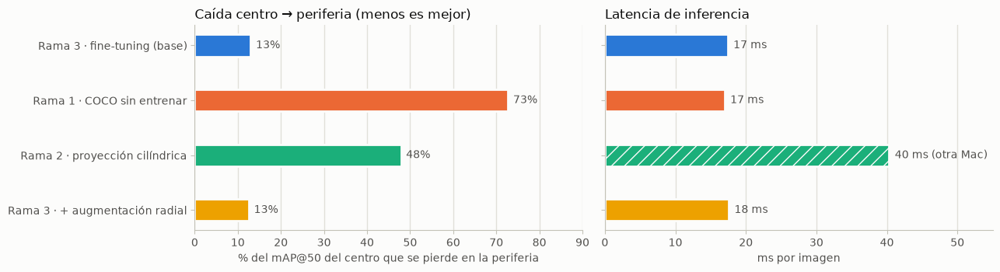

In [62]:
fig, axs = plt.subplots(1, 2, figsize=(13, 3.6), facecolor=SUPERFICIE)
pos = np.arange(len(SERIES))[::-1]

ax = axs[0]
estilo(ax, grilla="x")
for p, (fila, etiqueta, color, _) in zip(pos, SERIES):
    caida = 100 * (1 - comp.loc[fila, "mAP50 periferia"] / comp.loc[fila, "mAP50 centro"])
    ax.barh(p, caida, height=0.4, color=color, edgecolor=SUPERFICIE, linewidth=2)
    ax.text(caida + 1.2, p, f"{caida:.0f}%", va="center", color=TINTA2, fontsize=10)
ax.set_yticks(pos, [s[1] for s in SERIES])
ax.set_xlim(0, 90)
ax.set_xlabel("% del mAP@50 del centro que se pierde en la periferia", color=TINTA2)
ax.set_title("Caída centro → periferia (menos es mejor)", loc="left", color=TINTA, fontsize=12)

ax = axs[1]
estilo(ax, grilla="x")
for p, (fila, etiqueta, color, _) in zip(pos, SERIES):
    ms = comp.loc[fila, "ms_total"]
    otra_maquina = fila == "rama2_cilindrica"
    ax.barh(p, ms, height=0.4, color=color, edgecolor=SUPERFICIE, linewidth=2, hatch="//" if otra_maquina else None)
    ax.text(ms + 0.8, p, f"{ms:.0f} ms" + (" (otra Mac)" if otra_maquina else ""), va="center", color=TINTA2, fontsize=10)
ax.set_yticks(pos, [""] * len(SERIES))
ax.set_xlim(0, 55)
ax.set_xlabel("ms por imagen", color=TINTA2)
ax.set_title("Latencia de inferencia", loc="left", color=TINTA, fontsize=12)

fig.tight_layout()
fig.savefig(SALIDAS / "test_caida_latencia.png", dpi=200, facecolor=SUPERFICIE, bbox_inches="tight")
plt.show()

### 3. Por cámara y por clase

mAP@50 en test separado por cámara (izquierda) y AP@50 por clase (derecha). Las cámaras laterales (MVL, MVR) tienen casi todos los objetos en la periferia, así que son las que más dependen de cómo cada estrategia maneja la distorsión. La rama 2 aparece por cámara con los números de su notebook; por clase no hay datos de la rama 2. El valor sobre cada barra azul es el de la rama 3 (`base`); el resto está en las tablas de abajo.

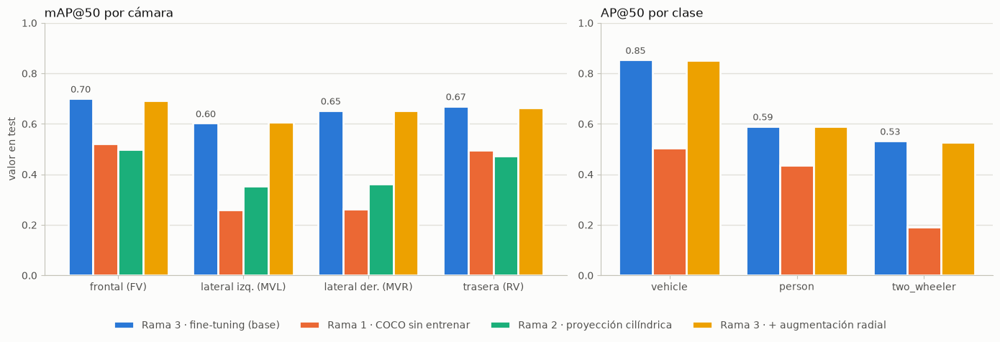

,mAP50 FV,mAP50 MVL,mAP50 MVR,mAP50 RV
Rama 3 · fine-tuning (base),0.701,0.603,0.653,0.671
Rama 1 · COCO sin entrenar,0.521,0.259,0.264,0.495
Rama 2 · proyección cilíndrica,0.498,0.353,0.363,0.474
Rama 3 · + augmentación radial,0.693,0.606,0.651,0.664


,AP50 vehicle,AP50 person,AP50 two_wheeler
Rama 3 · fine-tuning (base),0.854,0.591,0.533
Rama 1 · COCO sin entrenar,0.506,0.436,0.191
Rama 3 · + augmentación radial,0.852,0.590,0.526


In [63]:
# predicciones de test: las del kernel si ya se corrio la celda de test; si no, las guardadas en outputs/rama3/preds
if "preds_test" in globals() and "test" in globals():
    PT, TT = preds_test, test
else:
    TT = cargar_test()
    PT = {}
    for n in ("yolo11m_coco", "rama3_base", "rama3_radial"):
        archivos = sorted((SALIDAS / "preds").glob(f"{n}_*_test_{len(TT)}.pkl"), key=lambda f: f.stat().st_mtime)
        if archivos:
            PT[n] = con_conf(pd.read_pickle(archivos[-1]))

CLAVE = {"rama1_baseline (recalculado)": "yolo11m_coco", "rama3_base": "rama3_base", "rama3_radial": "rama3_radial"}
CAMARAS = ["FV", "MVL", "MVR", "RV"]
RAMA2_CAMARA = {"FV": 0.498, "MVL": 0.353, "MVR": 0.363, "RV": 0.474}  # mAP@50 de yolo11m en test, notebook de la rama 2

por_camara, por_clase = {}, {}
for fila, *_ in SERIES:
    if fila == "rama2_cilindrica":
        por_camara[fila] = [RAMA2_CAMARA[c] for c in CAMARAS]
    elif CLAVE.get(fila) in PT:
        p = PT[CLAVE[fila]]
        por_camara[fila] = [evaluar(p, TT[TT["camera"] == c])[0] for c in CAMARAS]
        por_clase[fila] = [evaluar(*solo_clase(p, TT, c))[0] for c in range(len(CLASES))]


def columnas(ax, grupos, valores, titulo):
    series = [s for s in SERIES if s[0] in valores]
    ancho = 0.8 / len(series)
    xg = np.arange(len(grupos))
    for i, (fila, etiqueta, color, _) in enumerate(series):
        xs = xg - 0.4 + ancho * (i + 0.5)
        ax.bar(xs, valores[fila], width=ancho, color=color, edgecolor=SUPERFICIE, linewidth=2, label=etiqueta)
        if fila == "rama3_base":
            for xx, v in zip(xs, valores[fila]):
                ax.text(xx, v + 0.015, f"{v:.2f}", ha="center", va="bottom", color=TINTA2, fontsize=9)
    ax.set_xticks(xg, grupos)
    ax.set_ylim(0, 1)
    ax.set_title(titulo, loc="left", color=TINTA, fontsize=12)


fig, axs = plt.subplots(1, 2, figsize=(14, 4.6), facecolor=SUPERFICIE, gridspec_kw={"width_ratios": [4, 3]})
for ax in axs:
    estilo(ax)
columnas(axs[0], ["frontal (FV)", "lateral izq. (MVL)", "lateral der. (MVR)", "trasera (RV)"], por_camara, "mAP@50 por cámara")
columnas(axs[1], CLASES, por_clase, "AP@50 por clase")
axs[0].set_ylabel("valor en test", color=TINTA2)
manijas, etiquetas = axs[0].get_legend_handles_labels()
fig.legend(manijas, etiquetas, loc="lower center", ncol=len(manijas), frameon=False, labelcolor=TINTA2, bbox_to_anchor=(0.5, -0.04))
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig(SALIDAS / "test_camara_clase.png", dpi=200, facecolor=SUPERFICIE, bbox_inches="tight")
plt.show()

nombres = {s[0]: s[1] for s in SERIES}
tabla_camara = pd.DataFrame(por_camara, index=CAMARAS).T.rename(index=nombres)
tabla_clase = pd.DataFrame(por_clase, index=CLASES).T.rename(index=nombres)
tabla_camara.to_csv(SALIDAS / "test_por_camara.csv")
tabla_clase.to_csv(SALIDAS / "test_por_clase.csv")
display(tabla_camara.round(3).rename(columns=lambda c: f"mAP50 {c}"))
display(tabla_clase.round(3).rename(columns=lambda c: f"AP50 {c}"))

### Cómo leer las tres gráficas

* **Gráfica 1.** La rama 1 cae en picada hacia la periferia, la rama 2 cae menos y la rama 3 queda casi plana: es el resultado central del trabajo. Las líneas de `base` y `radial` van prácticamente superpuestas, porque en las cámaras del dataset las dos variantes rinden igual.
* **Gráfica 2, izquierda.** Resume la gráfica 1 en un número por modelo: el porcentaje del desempeño que se pierde en los bordes. La rama 3 pierde una fracción de lo que pierden las ramas 1 y 2.
* **Gráfica 2, derecha.** La rama 3 cuesta lo mismo que el detector sin entrenar: es el mismo modelo con otros pesos y no agrega preprocesamiento.
* **Gráfica 3.** Muestra dónde está la ganancia: en las cámaras laterales y en las clases que el modelo de COCO detectaba peor.

Todo lo de esta sección es test, usado una sola vez y con los modelos elegidos en validación. Ningún número de acá se usó para tomar decisiones.